# KV-cache compression diagnostics on Qwen3-4B: T4 / L4 · E0–E6 + memory and latency

This notebook runs the follow-up experiments of the ILF project on Qwen3-4B. It tests why
ILF-diversified selection does not help retrieval from a reused prefix, and what does: layer coverage
(E1), cross-layer consistency (E2), the scoring signal (E3), the haystack (E4), precision vs eviction
(E5) and diversity over positions or content (E6), plus memory and decode latency. MMLU and LongBench
are optional.

**How to run**

1. **GPU.** In Colab select **Runtime → Change runtime type → T4 GPU** (16 GB) or **L4 GPU** (24 GB).
   The default is `MODEL_ID = "Qwen/Qwen3-4B"`, keeping the Qwen3 family. Its approximately 4.02B parameters
   occupy about 7.5 GiB in FP16/BF16, before the KV cache, activations and CUDA workspace.
   Model weights remain at 16 bits so the KV-compression comparisons keep their original meaning.
2. **Automatic hardware settings.** `GPU_PROFILE = "auto"` selects the T4 profile below 22 GiB VRAM and
   the L4 profile at or above 22 GiB. T4 uses FP16; L4 uses native BF16. The memory benchmark uses
   batch 1 × 2,048 tokens on T4, or batch 2 × 4,096 on L4 (the context cap reserves space for decode).
   Set `GPU_PROFILE = "t4"` to use the smaller workload on either card. Free memory is printed in §8.
3. **First run.** Set `PRESET = "smoke"` in §2, keep the 4B model, and *Run all* to check loading,
   digit tokenization, compression and decoding on your actual GPU. Smoke results use separate folders.
   An optional faster download is `MODEL_ID = "Qwen/Qwen3-0.6B"`; restore the 4B ID for the real run.
4. **Full run.** The saved default is `PRESET = "full"`. All E0–E6 experiments and the memory benchmark
   stay enabled; MMLU and LongBench stay optional. The research workload (30 documents, 20 facts,
   approximately 3,000 filler tokens) is unchanged. This is still a long experiment: use the first E0
   arms' printed timings to estimate your runtime. Smaller weights save memory, but the layer count
   and KV dimensions match Qwen3-8B, so KV-cache size does not shrink with the parameter count.
5. **Resume.** Each finished arm is saved to Google Drive in a model- and hardware-profile-specific
   folder. After a disconnect, rerun the cells: finished arms load from disk. Delete an arm's file
   to rerun it. Keep the headroom gate enabled for full runs; a small model's retrieval quality must
   be measured before interpreting compression results.

The 16-bit weight and KV figures above are estimates, not measured GPU peaks. §8 checks the attention
kernels and §17 measures the configured workload. Sources: [Qwen3-4B model card](https://huggingface.co/Qwen/Qwen3-4B)
and [model configuration](https://huggingface.co/Qwen/Qwen3-4B/blob/main/config.json).

**Sections**

| § | What | Default |
|---|---|---|
| 1–3 | install, configuration, results folder and resume | always |
| 4–7 | compression code: attention backend, scoring, packed cache, prefill/compress | always |
| 8 | load model and load-time checks | always |
| 9 | experiment harness, harness checks, headroom gate | always |
| 10 | E0 budget sweep (sets the probe budgets) | on |
| 11 | E5 tier split | on |
| 12 | E2 consistency sweep | on |
| 13 | E1 layer coverage | on |
| 14 | E3 scoring signal | on |
| 15 | E4 haystack | on |
| 16 | E6 position and content diversity | on |
| 17 | memory and decode latency | on |
| 18 | MMLU, LongBench | off |
| 19 | summary and export | always |

**Metrics.** Every question is scored *teacher-forced* in one forward pass. `gold_nll` is the mean negative
log-likelihood of the gold digit tokens (chance is ln 10 ≈ 2.30 nats when each digit is one token, which §9
checks). `tf_digit_acc` / `tf_exact` say whether the greedy prediction is right at each / every digit given
the gold digits before it. E0 also decodes freely (`correct`, `digit_acc`). `needle_kept_frac` is the share
of (layer, fact-token) pairs that survive; `code_layers_full` the number of layers that still hold a fact's
whole code; `fact_eviction_ratio` = (fact-token eviction rate) / (average eviction rate), so 1 means the
scorer evicts facts as often as any token, above 1 that it prefers to evict them.

**Implementation notes** (unchanged from the starter notebook)
* A custom attention backend (`kv_compress`, SDPA-based) records $a_{i,l}$ during prefill: the attention
  mass that the last `OBS_WINDOW` prefix queries put on each token, averaged over query heads (SnapKV-style).
* Keys are cached after RoPE and new tokens are fed with their *original* position ids, so eviction never
  shifts positions.
* The first `SINK_TOKENS` and last `OBS_WINDOW` prefix tokens always stay at 16 bits; their bytes count
  against the budget.
* Quantization is asymmetric min-max with fp16 scale and zero: per channel over 32-token groups for keys
  (KIVI-style), per token over 32-channel groups for values. 4-bit codes are packed two per byte, 2-bit
  codes four per byte.
* Prefix caching: each document is compressed **once, before any question is seen**, and the same
  compressed prefix answers every question about it.

## 1. Install and imports
`lm_eval` is installed later, in §18, and only when MMLU or LongBench is switched on. If installing changes
a package your kernel already imported, restart the kernel and run again.

In [ ]:
import os
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")  # reduce fragmentation on T4 / L4

%pip install -q "torch>=2.6" "transformers==4.57.1" "accelerate>=0.26.0" datasets sentencepiece pandas matplotlib

import json, math, time, random, re, gc, hashlib, platform, shutil, subprocess, sys
from collections import defaultdict
from dataclasses import dataclass, asdict
from datetime import datetime, timezone
from pathlib import Path
from typing import Optional, Union
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from transformers import AutoModelForCausalLM, AutoTokenizer, set_seed
from importlib.metadata import version

VERSIONS = {name: version(name) for name in ["torch", "transformers", "accelerate", "pandas", "numpy"]}
print(VERSIONS)
if torch.cuda.is_available():
    _p = torch.cuda.get_device_properties(0)
    GPU_INFO = {"name": _p.name, "memory_GiB": round(_p.total_memory / 2**30, 1),
                "bf16": torch.cuda.is_bf16_supported(including_emulation=False), "cuda": torch.version.cuda}
else:
    GPU_INFO = {"name": "cpu"}
print("GPU:", GPU_INFO)

{'torch': '2.14.1+cu130', 'transformers': '4.57.1', 'accelerate': '1.15.0', 'pandas': '2.2.3', 'numpy': '2.4.6'}
GPU: {'name': 'NVIDIA L4', 'memory_GiB': 22.0, 'bf16': True, 'cuda': '13.0'}


## 2. Configuration
Every knob lives in this cell. The default full run uses Qwen3-4B with automatic T4/L4 benchmark settings.
`PRESET = "smoke"` shrinks the workload for an initial check, while still loading the selected model.
Results are separated by model, hardware profile and smoke/full preset. `GPU_PROFILE = "t4"` forces
the conservative benchmark workload on either card; `"l4"` requests the larger workload.


In [ ]:
# ---- What to run ----
PRESET = "full"             # "smoke": tiny settings, minutes; "full": the real run
MODEL_ID = "Qwen/Qwen3-4B"  # Qwen3 family; ~7.5 GiB of 16-bit weights
GPU_PROFILE = "auto"        # "auto", "t4" (conservative), or "l4" (larger memory benchmark)
if GPU_PROFILE not in {"auto", "t4", "l4"}:
    raise ValueError("GPU_PROFILE must be 'auto', 't4', or 'l4'")
RESOLVED_GPU_PROFILE = ("l4" if GPU_INFO.get("memory_GiB", 0) >= 22 else "t4") if GPU_PROFILE == "auto" else GPU_PROFILE
# Experiments, listed in run (priority) order. E0 sets the probe budgets that E2, E3 and E6 use.
RUN_E0 = RUN_E5 = RUN_E2 = RUN_E1 = RUN_E3 = RUN_E4 = RUN_E6 = True
RUN_BENCH = True            # memory and decode latency (§17); most reliable in a fresh runtime
RUN_MMLU = False            # optional (§18)
RUN_LONGBENCH = False       # optional (§18)

# ---- Where results go ----
USE_DRIVE = True            # Colab: save on Google Drive, so a disconnect loses at most one arm
DRIVE_DIR = "/content/drive/MyDrive/kv_cache_results2"
LOCAL_DIR = "results"       # used outside Colab or when USE_DRIVE is False
DRIVE_DIR += f"_{RESOLVED_GPU_PROFILE}"
LOCAL_DIR += f"_{RESOLVED_GPU_PROFILE}"

# ---- Compression hyperparameters (unchanged from the first run) ----
SINK_TOKENS = 4
OBS_WINDOW = 32             # last W prefix tokens: always kept at 16 bits; their queries give a_{i,l}
POOL_KERNEL = 7
LAMBDA = 1.0                # main ILF weight
TIER_SPLIT = (1 / 3, 1 / 3, 1 / 3)  # budget share of the 16 / 8 / 4-bit tiers in mixed precision
QUERY_AWARE = False         # optional benchmarks: compress the prefix before the question is seen

# ---- Retrieval documents ----
HAYSTACK = "natural"        # primary haystack for E0-E3 and E5: "natural" (WikiText prose) or "repeat" (filler log)
EXP_DOCS = 30               # documents per arm
RETRIEVAL_FACTS = 20        # facts (= questions) per document
RETRIEVAL_TOKENS = 3000     # document length in tokens
EXP_GENERATE = False        # E0 always decodes; the other experiments are teacher-forced only

# ---- Budgets (fractions of fp16 KV bytes; "int4"/"int8" = the bytes of uniform 4/8-bit quantization) ----
KEEP_GRID = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]  # E0 and E4 (E4 adds 0.1 and 0.2)
E5_BUDGETS = [0.1, 0.2, "int4"]
PROBE_BUDGETS = [0.6, 0.8]  # E2, E3, E6; replaced by E0's choice when AUTO_PROBE_BUDGETS
AUTO_PROBE_BUDGETS = True
E1_LAYER_STRIDE = 1         # E1 single-layer scan: 1 = every layer, 2 = every second layer (half the arms)

# ---- Gate before the experiments (§9) ----
HEADROOM_MIN = 0.7          # full-cache teacher-forced exact match needed on the primary haystack
ENFORCE_HEADROOM = True     # False: warn instead of stopping

# ---- Memory and latency (§17) ----
# Bound peak prefill memory: compression happens AFTER the full cache is created.
BENCH_BATCH, BENCH_SEQ_LEN = (1, 2048) if RESOLVED_GPU_PROFILE == "t4" else (2, 4096)
BENCH_DECODE_TOKENS = 64
BENCH_REPEATS = 3           # repeats, each in a freshly shuffled method order

# ---- Optional benchmarks (§18) ----
MAX_INPUT_TOKENS = 4096     # also caps retrieval documents (RETRIEVAL_TOKENS + 64)
MMLU_TASKS, MMLU_LIMIT, MMLU_FEWSHOT = ["mmlu"], 10, 5  # limit is per subject (57 subjects)
LONGBENCH_TASKS = ["longbench_hotpotqa", "longbench_2wikimqa", "longbench_multifieldqa_en",
                   "longbench_qasper", "longbench_passage_retrieval_en"]
LONGBENCH_LIMIT = 200       # per task
LONGBENCH_CHAT_TEMPLATE = True  # wrap prompts in the chat template with thinking off (post-trained models)
LONGBENCH_MIN_FULL = 0.10   # drop a task whose full-cache score is below max(this, 2 x chance)

SEED = 42
# (layers, KV heads, head dim), from each model's published config.json.
EXPECTED_DIMS = {"Qwen/Qwen3-4B": (36, 8, 128), "Qwen/Qwen3-0.6B": (28, 8, 128),
                 "Qwen/Qwen3-8B": (36, 8, 128), "Qwen/Qwen2.5-0.5B": (24, 2, 64)}

if PRESET == "smoke":
    EXP_DOCS, RETRIEVAL_FACTS, RETRIEVAL_TOKENS = 1, 6, 800
    KEEP_GRID, E5_BUDGETS, PROBE_BUDGETS = [0.5], [0.2], [0.5]
    BENCH_BATCH, BENCH_SEQ_LEN, BENCH_DECODE_TOKENS, BENCH_REPEATS = 1, 512, 8, 1
    MAX_INPUT_TOKENS = 2048
    MMLU_TASKS, MMLU_LIMIT, MMLU_FEWSHOT = ["mmlu_abstract_algebra"], 4, 0
    LONGBENCH_TASKS, LONGBENCH_LIMIT = ["longbench_hotpotqa"], 2
    ENFORCE_HEADROOM = False
    DRIVE_DIR, LOCAL_DIR = DRIVE_DIR + "_smoke", LOCAL_DIR + "_smoke"
elif PRESET != "full":
    raise ValueError(f"PRESET must be 'smoke' or 'full', not {PRESET!r}")

CONFIG_KEYS = ["PRESET", "MODEL_ID", "GPU_PROFILE", "RESOLVED_GPU_PROFILE", "RUN_E0", "RUN_E5", "RUN_E2", "RUN_E1", "RUN_E3", "RUN_E4", "RUN_E6",
               "RUN_BENCH", "RUN_MMLU", "RUN_LONGBENCH", "SINK_TOKENS", "OBS_WINDOW", "POOL_KERNEL", "LAMBDA",
               "TIER_SPLIT", "QUERY_AWARE", "HAYSTACK", "EXP_DOCS", "RETRIEVAL_FACTS", "RETRIEVAL_TOKENS",
               "EXP_GENERATE", "KEEP_GRID", "E5_BUDGETS", "PROBE_BUDGETS", "AUTO_PROBE_BUDGETS", "E1_LAYER_STRIDE",
               "HEADROOM_MIN", "ENFORCE_HEADROOM", "BENCH_BATCH", "BENCH_SEQ_LEN", "BENCH_DECODE_TOKENS",
               "BENCH_REPEATS", "MAX_INPUT_TOKENS", "MMLU_TASKS", "MMLU_LIMIT", "MMLU_FEWSHOT", "LONGBENCH_TASKS",
               "LONGBENCH_LIMIT", "LONGBENCH_CHAT_TEMPLATE", "LONGBENCH_MIN_FULL", "SEED"]
set_seed(SEED)
print(f"PRESET={PRESET}  MODEL_ID={MODEL_ID}  GPU_PROFILE={RESOLVED_GPU_PROFILE}  "
      f"HAYSTACK={HAYSTACK}  docs={EXP_DOCS} x {RETRIEVAL_FACTS} facts")
print(f"Memory benchmark: batch {BENCH_BATCH} x {BENCH_SEQ_LEN} tokens, {BENCH_DECODE_TOKENS} decode steps")

PRESET=full  MODEL_ID=Qwen/Qwen3-4B  GPU_PROFILE=l4  HAYSTACK=natural  docs=30 x 20 facts
Memory benchmark: batch 2 x 4096 tokens, 64 decode steps


## 3. Results folder, run manifest and resume
Results go to `<results>_<gpu_profile>/<model>/` (with `_smoke` for smoke runs). `run_manifest.json` records versions, GPU, every knob, the probe budgets
actually used and start/end times per experiment. Per-arm checkpoints live in `<results>_<gpu_profile>/<model>/<exp>/arms/`
(written by `run_arms` in §9).

In [ ]:
def _in_colab():
    try:
        import google.colab  # noqa: F401
        return True
    except ImportError:
        return False


if USE_DRIVE and _in_colab():
    if not Path("/content/drive/MyDrive").exists():
        from google.colab import drive
        drive.mount("/content/drive")
    RESULTS_DIR = Path(DRIVE_DIR)
else:
    RESULTS_DIR = Path(LOCAL_DIR)
EXP_OUT = RESULTS_DIR / MODEL_ID.replace("/", "__")
EXP_OUT.mkdir(parents=True, exist_ok=True)
MANIFEST_PATH = EXP_OUT / "run_manifest.json"
print("Results folder:", EXP_OUT.resolve())


def _now():
    return datetime.now(timezone.utc).isoformat(timespec="seconds")


def _git_commit():
    try:
        out = subprocess.run(["git", "rev-parse", "HEAD"], capture_output=True, text=True, timeout=5)
        return out.stdout.strip() or None
    except Exception:
        return None


def read_manifest():
    return json.loads(MANIFEST_PATH.read_text()) if MANIFEST_PATH.exists() else {}


def update_manifest(**entries):
    """Merge `entries` into run_manifest.json; dict values are merged one level deep."""
    m = read_manifest()
    for k, v in entries.items():
        if isinstance(v, dict) and isinstance(m.get(k), dict):
            m[k].update(v)
        else:
            m[k] = v
    MANIFEST_PATH.write_text(json.dumps(m, indent=2, default=str))
    return m


_EXP_T0 = {}


def exp_start(name):
    _EXP_T0[name] = time.time()
    update_manifest(experiments={name: {"started": _now()}})
    print(f"===== {name} started {_now()} =====")


def exp_end(name):
    minutes = (time.time() - _EXP_T0.get(name, time.time())) / 60
    m = read_manifest().get("experiments", {}).get(name, {})
    update_manifest(experiments={name: {**m, "finished": _now(), "minutes_this_session": round(minutes, 1)}})
    print(f"===== {name} finished in {minutes:.1f} min =====")


def save_table(df, model_id, name):
    path = RESULTS_DIR / model_id.replace("/", "__") / f"{name}.csv"
    path.parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(path, index=False)
    print(f"Saved {path}")


update_manifest(model_id=MODEL_ID, preset=PRESET, versions=VERSIONS, python=platform.python_version(),
                gpu=GPU_INFO, notebook_git_commit=_git_commit(), last_session_started=_now(),
                config={k: globals()[k] for k in CONFIG_KEYS})

Results folder: /content/drive/MyDrive/kv_cache_results2_l4/Qwen__Qwen3-4B


{'model_id': 'Qwen/Qwen3-4B',
 'preset': 'full',
 'versions': {'torch': '2.14.1+cu130',
  'transformers': '4.57.1',
  'accelerate': '1.15.0',
  'pandas': '2.2.3',
  'numpy': '2.4.6'},
 'python': '3.13.16',
 'gpu': {'name': 'NVIDIA L4',
  'memory_GiB': 22.0,
  'bf16': True,
  'cuda': '13.0'},
 'notebook_git_commit': None,
 'last_session_started': '2026-11-18T06:21:41+00:00',
 'config': {'PRESET': 'full',
  'MODEL_ID': 'Qwen/Qwen3-4B',
  'GPU_PROFILE': 'auto',
  'RESOLVED_GPU_PROFILE': 'l4',
  'RUN_E0': True,
  'RUN_E5': True,
  'RUN_E2': True,
  'RUN_E1': True,
  'RUN_E3': True,
  'RUN_E4': True,
  'RUN_E6': True,
  'RUN_BENCH': True,
  'RUN_MMLU': False,
  'RUN_LONGBENCH': False,
  'SINK_TOKENS': 4,
  'OBS_WINDOW': 32,
  'POOL_KERNEL': 7,
  'LAMBDA': 1.0,
  'TIER_SPLIT': (0.3333333333333333, 0.3333333333333333, 0.3333333333333333),
  'QUERY_AWARE': False,
  'HAYSTACK': 'natural',
  'EXP_DOCS': 30,
  'RETRIEVAL_FACTS': 20,
  'RETRIEVAL_TOKENS': 3000,
  'EXP_GENERATE': False,
  'KEEP_GRI

## 4. Attention backend: recording $a_{i,l}$
`kv_compression_attention` replaces eager attention. While `RECORDER` is active (only during the prefill
of a compressed method), each layer stores
$a_{i,l} = \operatorname{mean}_{h,\,q \in \text{window}} \operatorname{softmax}(q K^\top/\sqrt{d})_i$.

In [ ]:
import math
import torch.nn.functional as F
from transformers import AttentionInterface


class AttentionScoreRecorder:
    """While active, stores a_{i,l} for every layer l: attention from the last `window`
    query positions to the first `n_keys` keys (default: all), reduced over query heads
    and window queries.

    reduce: "mean"          average over heads and window queries (SnapKV-style, the default)
            "mean_visible"  like "mean", but each key is averaged only over the window queries
                            that can see it (needed when the window covers the whole prefix)
            "max"           strongest single (head, query) pair (KVzip-style)"""

    def __init__(self):
        self.active, self.window, self.n_keys, self.reduce, self.scores = False, 32, None, "mean", {}

    def start(self, window, n_keys=None, reduce="mean"):
        self.active, self.window, self.n_keys, self.reduce, self.scores = True, window, n_keys, reduce, {}

    def stop(self):
        scores, self.active, self.scores = self.scores, False, {}
        return scores


RECORDER = AttentionScoreRecorder()
SCORE_QUERY_CHUNK = 128  # window queries scored at a time; bounds memory for long scoring windows


def _window_attention(query, key, scaling, window, n_keys=None, reduce="mean"):
    """[b, Hq, q, d] x [b, Hkv, k, d] -> [b, n_keys] attention mass from the last `window` queries.
    Grouped-query heads are handled without materialising repeated keys, and the window is
    processed in chunks of SCORE_QUERY_CHUNK queries."""
    b, hq, q_len, d = query.shape
    hk, k_len = key.shape[1], key.shape[2]
    n_rep, w = hq // hk, min(window, q_len)
    n_keys = k_len if n_keys is None else min(n_keys, k_len)
    key_t = key.float().transpose(-1, -2)
    key_pos = torch.arange(k_len, device=query.device)
    out = torch.zeros(b, n_keys, device=query.device)
    for start in range(q_len - w, q_len, SCORE_QUERY_CHUNK):
        stop = min(start + SCORE_QUERY_CHUNK, q_len)
        q = query[:, :, start:stop].float().reshape(b, hk, n_rep * (stop - start), d)  # rows ordered (rep, query pos)
        logits = torch.matmul(q, key_t) * scaling
        q_pos = (torch.arange(start, stop, device=query.device) + (k_len - q_len)).repeat(n_rep)
        logits.masked_fill_(key_pos[None, :] > q_pos[:, None], float("-inf"))
        probs = logits.softmax(-1)[..., :n_keys]
        if reduce == "max":
            out = torch.maximum(out, probs.amax(dim=(1, 2)))
        else:
            out += probs.sum(dim=(1, 2))
    if reduce == "max":
        return out
    if reduce == "mean_visible":  # number of window queries at or after each key position
        visible = (k_len - key_pos[:n_keys].clamp_min(k_len - w)).clamp_min(1)
        return out / (hk * n_rep * visible)
    return out / (hk * n_rep * w)


def kv_compression_attention(module, query, key, value, attention_mask, scaling=None, dropout=0.0, **kwargs):
    """SDPA attention that (1) optionally records window attention scores and
    (2) builds its own mask, so it works on caches whose length no longer equals the
    position index (after eviction). Assumes unpadded batches (no left padding)."""
    scaling = scaling if scaling is not None else 1.0 / math.sqrt(query.shape[-1])
    if RECORDER.active:
        RECORDER.scores[module.layer_idx] = _window_attention(query, key, scaling, RECORDER.window,
                                                              RECORDER.n_keys, RECORDER.reduce)
    n_rep = query.shape[1] // key.shape[1]
    if n_rep > 1:
        key = key.repeat_interleave(n_rep, dim=1)
        value = value.repeat_interleave(n_rep, dim=1)
    q_len, k_len = query.shape[2], key.shape[2]
    if q_len == 1:  # decoding: every retained cache entry is visible
        out = F.scaled_dot_product_attention(query, key, value, scale=scaling)
    elif q_len == k_len:  # prefill with an empty cache
        out = F.scaled_dot_product_attention(query, key, value, is_causal=True, scale=scaling)
    else:  # several new tokens on top of a (compressed) cache: causal among the new tokens
        q_pos = torch.arange(k_len - q_len, k_len, device=query.device)
        allowed = torch.arange(k_len, device=query.device)[None, :] <= q_pos[:, None]
        out = F.scaled_dot_product_attention(query, key, value, attn_mask=allowed, scale=scaling)
    return out.transpose(1, 2).contiguous(), None


AttentionInterface.register("kv_compress", kv_compression_attention)
print("Registered attention backend 'kv_compress'.")

Registered attention backend 'kv_compress'.


## 5. ILF scoring and bit allocation
For every layer $l$ and candidate token $i$:

$$d_i=\sum_{l=1}^{L}\mathbf 1[a_{i,l}>\tau_l],\qquad \mathrm{ILF}_i=\log\frac{L+1}{d_i+1},\qquad S_{i,l}=a_{i,l}\,(1+\lambda\,\mathrm{ILF}_i)$$

By default $\tau_l$ is layer $l$'s $(1-k)$ quantile of attention, where $k$ is the fraction of tokens the
budget lets us keep. So $d_i$ counts the layers in which plain attention selection would have kept
token $i$. Tokens that every layer already wants get a small ILF boost; tokens that only a few layers
find important get a larger one.

* **select**: per layer, the top tokens by $S_{i,l}$ are kept at 16 bits; the rest are evicted.
* **mixed**: per layer, tokens ranked by $S_{i,l}$ fill a 16-bit tier, then an 8-bit tier, then a 4-bit
  tier; the rest get 0 bits (evicted). `TIER_SPLIT` sets how the byte budget is shared across tiers.
* $\lambda = 0$ recovers the plain attention-based baselines.

In [ ]:
from dataclasses import dataclass
from typing import Optional, Union


@dataclass(frozen=True)
class KVCompressionConfig:
    """One compression method.

    method:  "full"   - no compression (baseline)
             "select" - dynamic selection: keep the top tokens at 16 bits, evict the rest
             "quant"  - uniform quantization of every token to `quant_bits`
             "mixed"  - mixed precision: tokens ranked by score get 16 / 8 / 4 / 0 bits
    budget:  fraction of the fp16 KV-cache bytes to keep, or "int4"/"int8" to match the
             byte footprint of uniform 4/8-bit quantization on the same input.
    lam:     lambda in S_{i,l} = a_{i,l} (1 + lambda * ILF_i). lam = 0 is plain attention scoring.
    score_mode: how per-layer attention a_{i,l} becomes the selection score (see `selection_scores`):
             "ilf" (default), "ilf_gated", "lf", "mix", "segment", "idf", "random_shared", "random_layer".
    """

    name: str
    method: str = "full"
    budget: Union[float, str] = 1.0
    lam: float = 0.0
    quant_bits: int = 8
    tier_split: tuple = (1 / 3, 1 / 3, 1 / 3)  # share of the budget spent on 16 / 8 / 4-bit tiers
    sink_tokens: int = 4    # first tokens, always kept at 16 bits (attention sinks)
    window: int = 32        # last tokens, always kept at 16 bits; their queries score the rest
    pool_kernel: int = 7    # 1-D average pooling of scores along tokens (SnapKV-style); 1 disables
    tau_quantile: Optional[float] = None  # per-layer tau_l quantile; None -> 1 - keep fraction
    score_mode: str = "ilf"
    layer_mix: float = 0.0  # "mix": 0 = every layer ranks on its own, 1 = one shared ranking for all layers
    n_segments: int = 16    # "segment": number of contiguous prefix blocks that get equal keep quotas
    seed: int = 0           # "random_*" modes


def bytes_ratio(bits, head_dim, group=32):
    """Approximate bytes per stored token relative to fp16, including the fp16 scale + zero
    stored for every group of `group` elements (keys and values alike)."""
    if bits == 16:
        return 1.0
    if bits == 0:
        return 0.0
    return (bits / 8 + 4 / min(group, head_dim)) / 2


def resolve_budget(cfg, n_tokens, n_forced, head_dim):
    if isinstance(cfg.budget, str):  # "int4" / "int8": match uniform quantization
        bits = int(cfg.budget.removeprefix("int"))
        return (n_forced + (n_tokens - n_forced) * bytes_ratio(bits, head_dim)) / n_tokens
    return float(cfg.budget)


def tier_counts(cfg, n_tokens, n_forced, head_dim):
    """Number of candidate tokens (outside sinks/window) to store at 16, 8 and 4 bits."""
    n_cand = n_tokens - n_forced
    budget = resolve_budget(cfg, n_tokens, n_forced, head_dim)
    remaining = max(budget * n_tokens - n_forced, 0.0)  # in fp16-token units
    if cfg.method == "select":
        return min(n_cand, int(remaining)), 0, 0
    counts, left = [], n_cand
    for share, bits in zip(cfg.tier_split, (16, 8, 4)):
        n = min(left, int(remaining * share / bytes_ratio(bits, head_dim)))
        counts.append(n)
        left -= n
    return tuple(counts)


def ilf_diversified_scores(attn, lam, keep_fraction, tau_quantile=None):
    """attn: a_{i,l} as [L, batch, tokens].
    d_i     = sum_l 1[a_{i,l} > tau_l]
    ILF_i   = log((L + 1) / (d_i + 1))
    S_{i,l} = a_{i,l} (1 + lam * ILF_i)
    tau_l defaults to layer l's (1 - keep_fraction) quantile, i.e. "token i would be kept
    by plain attention selection in layer l"."""
    n_layers = attn.shape[0]
    q = tau_quantile if tau_quantile is not None else 1.0 - keep_fraction
    q = min(max(q, 0.0), 1.0)
    tau = torch.quantile(attn, q, dim=-1, keepdim=True)
    d = (attn > tau).sum(0)
    ilf = torch.log((n_layers + 1) / (d.float() + 1))
    return attn * (1 + lam * ilf), d, ilf


def _rank01(x):
    """Rank of every entry along the last dim, scaled to [0, 1] (1 = largest)."""
    return x.argsort(-1).argsort(-1).float() / max(x.shape[-1] - 1, 1)


def selection_scores(attn, cfg, keep_fraction, token_ids=None):
    """Selection score S_{i,l} [L, batch, tokens] from attention a_{i,l}, by `cfg.score_mode`.

    "ilf"            a (1 + lam * ILF_i): the proposal. More cross-layer diversity as lam grows.
    "ilf_gated"      as "ilf", but tokens that no layer would keep (d_i = 0) get no boost.
    "lf"             a (1 + lam * log(1 + d_i)): the opposite of ILF, boosts tokens many layers want.
    "mix"            (1 - layer_mix) * r_{i,l} + layer_mix * mean_l r_{i,l}, r = per-layer rank in [0, 1].
                     layer_mix = 0 is plain attention; layer_mix = 1 keeps the same tokens in every layer.
    "segment"        rank of a_{i,l} inside its block of the prefix (`n_segments` equal blocks),
                     so every block keeps the same share of its tokens (diversity over positions).
    "idf"            a (1 + lam * log(M / count_i)), count_i = occurrences of token i's id among the
                     M candidates (diversity over content: literal tf-idf). Needs `token_ids` [batch, tokens].
    "random_shared"  random ranking shared by all layers.   "random_layer": independent per layer."""
    mode, n_tok = cfg.score_mode, attn.shape[-1]
    if mode == "ilf":
        return ilf_diversified_scores(attn, cfg.lam, keep_fraction, cfg.tau_quantile)[0]
    if mode in ("ilf_gated", "lf"):
        _, d, ilf = ilf_diversified_scores(attn, cfg.lam, keep_fraction, cfg.tau_quantile)
        boost = ilf * (d > 0) if mode == "ilf_gated" else torch.log1p(d.float())
        return attn * (1 + cfg.lam * boost)
    if mode == "mix":
        r = _rank01(attn)
        return (1 - cfg.layer_mix) * r + cfg.layer_mix * r.mean(0, keepdim=True)
    if mode == "segment":
        s = torch.empty_like(attn, dtype=torch.float32)
        edges = torch.linspace(0, n_tok, min(cfg.n_segments, n_tok) + 1).round().long().tolist()
        for lo, hi in zip(edges[:-1], edges[1:]):
            s[..., lo:hi] = _rank01(attn[..., lo:hi])
        return s
    if mode == "idf":
        counts = (token_ids[:, :, None] == token_ids[:, None, :]).sum(-1).float()  # [batch, tokens]
        return attn * (1 + cfg.lam * torch.log(n_tok / counts))
    if mode in ("random_shared", "random_layer"):
        g = torch.Generator().manual_seed(cfg.seed)
        shape = attn.shape if mode == "random_layer" else (1, *attn.shape[1:])
        return torch.rand(shape, generator=g).to(attn.device).expand(attn.shape)
    raise ValueError(f"unknown score_mode {mode!r}")


def allocate_bits(scores, n16, n8, n4):
    """scores [batch, tokens] -> bits [batch, tokens]: best n16 -> 16, next n8 -> 8, next n4 -> 4, rest 0."""
    b, m = scores.shape
    tiers = torch.zeros(m, dtype=torch.int16, device=scores.device)
    tiers[:n16] = 16
    tiers[n16:n16 + n8] = 8
    tiers[n16 + n8:n16 + n8 + n4] = 4
    order = scores.argsort(dim=-1, descending=True)
    return torch.zeros_like(order, dtype=torch.int16).scatter_(-1, order, tiers.expand(b, m).contiguous())


def make_config(name, method, budget=1.0, lam=0.0, **kw):
    defaults = dict(tier_split=TIER_SPLIT, sink_tokens=SINK_TOKENS, window=OBS_WINDOW, pool_kernel=POOL_KERNEL)
    return KVCompressionConfig(name, method, budget, lam, **{**defaults, **kw})


def budget_tag(b):
    return b if isinstance(b, str) else f"{b:.0%}"

## 6. Compressed cache with packed mixed-precision storage
`CompressedLayer` plugs into the Transformers `DynamicCache`. It holds a 16-bit block plus packed
8-, 4- and 2-bit blocks (with metadata) for retained tokens; evicted tokens are simply absent.
`CompressedPrefix.make_cache()` builds a fresh cache that shares the stored tensors, so one compressed
prefix can serve many queries without copying.

In [ ]:
from transformers.cache_utils import DynamicCache, DynamicLayer


QUANT_GROUP = 32  # keys: per-channel over groups of 32 tokens (KIVI-style); values: per-token, 32 channels


@dataclass
class QTensor:
    """Packed asymmetric min-max quantization with fp16 scale/zero per group.
    axis="channel": each channel is quantized over a group of `group` tokens (used for keys,
    which have outlier channels); axis="token": each token over `group` channels (values).
    4-bit codes are packed two per uint8 byte, so storage really shrinks."""

    data: torch.Tensor   # uint8 [b, h, n_padded, d] (or d/2 when 4-bit)
    scale: torch.Tensor
    zero: torch.Tensor
    bits: int
    axis: str
    group: int
    num_tokens: int

    @property
    def nbytes(self):
        return sum(t.numel() * t.element_size() for t in (self.data, self.scale, self.zero))

    def dequantize(self, dtype):
        q = self.data
        if self.bits == 4:
            q = torch.stack((q & 0xF, q >> 4), dim=-1).flatten(-2)
        elif self.bits == 2:
            q = torch.stack((q & 3, (q >> 2) & 3, (q >> 4) & 3, q >> 6), dim=-1).flatten(-2)
        b, h, n, d = q.shape
        shape = (b, h, n // self.group, self.group, d) if self.axis == "channel" else (b, h, n, d // self.group, self.group)
        x = q.to(dtype).reshape(shape) * self.scale.to(dtype) + self.zero.to(dtype)
        return x.reshape(b, h, n, d)[:, :, :self.num_tokens]


def quantize(x, bits, axis, group=QUANT_GROUP):
    assert bits in (2, 4, 8)
    b, h, n, d = x.shape
    xf = x.float()
    if axis == "channel":
        pad = (-n) % group  # pad by repeating the last token so it does not widen the range
        xf = torch.cat([xf, xf[:, :, -1:].expand(b, h, pad, d)], dim=2)
        xg, red = xf.reshape(b, h, (n + pad) // group, group, d), -2
    else:
        group = min(group, d)
        xg, red = xf.reshape(b, h, n, d // group, group), -1
    lo, hi = xg.amin(red, keepdim=True), xg.amax(red, keepdim=True)
    qmax = 2 ** bits - 1
    scale = ((hi - lo) / qmax).clamp_min(1e-5)
    q = torch.round((xg - lo) / scale).clamp_(0, qmax).to(torch.uint8).reshape(b, h, -1, d)
    if bits == 4:
        q = q[..., 0::2] | (q[..., 1::2] << 4)
    elif bits == 2:  # four codes per byte (head_dim must be a multiple of 4)
        q = q[..., 0::4] | (q[..., 1::4] << 2) | (q[..., 2::4] << 4) | (q[..., 3::4] << 6)
    return QTensor(q.contiguous(), scale.half(), lo.half(), bits, axis, group, n)


class CompressedLayer(DynamicLayer):
    """One layer's retained KV entries: a 16-bit part plus packed 8/4-bit parts.
    Newly generated tokens are appended to the 16-bit part. Keys are stored post-RoPE,
    so evicted/reordered entries keep their original positions."""

    def __init__(self, keys16, values16, quantized=()):
        super().__init__()
        self.dtype, self.device = keys16.dtype, keys16.device
        self.keys, self.values = keys16, values16
        self.quantized = list(quantized)  # [(QTensor keys, QTensor values), ...]
        self.is_initialized = True

    def update(self, key_states, value_states, cache_kwargs=None):
        self.keys = torch.cat([self.keys, key_states], dim=-2)
        self.values = torch.cat([self.values, value_states], dim=-2)
        if not self.quantized:
            return self.keys, self.values
        keys = [qk.dequantize(self.dtype) for qk, _ in self.quantized] + [self.keys]
        values = [qv.dequantize(self.dtype) for _, qv in self.quantized] + [self.values]
        return torch.cat(keys, dim=-2), torch.cat(values, dim=-2)

    def get_seq_length(self):
        return self.keys.shape[-2] + sum(qk.num_tokens for qk, _ in self.quantized)


def storage_bytes(layers):
    """KV bytes with 16-bit entries counted at 2 bytes (independent of compute dtype)."""
    total = 0
    for k, v, quantized in layers:
        total += 2 * (k.numel() + v.numel())
        total += sum(qk.nbytes + qv.nbytes for qk, qv in quantized)
    return total


@dataclass
class CompressedPrefix:
    """A compressed, reusable prefix cache. `make_cache()` returns a fresh cache for each
    query, so one compressed prefix can serve many queries (prefix caching)."""

    layers: list   # per layer: (keys16, values16, [(QTensor, QTensor), ...])
    length: int    # number of original prefix tokens = next position id
    stats: dict
    bits: Optional[torch.Tensor] = None  # the bit plan [L, batch, N]: 16 / 8 / 4 / 2 bits, 0 = evicted

    def make_cache(self):
        cache = DynamicCache()
        cache.layers = [CompressedLayer(k, v, q) for k, v, q in self.layers]
        return cache


def _gather_tokens(x, idx):
    return x.gather(2, idx[:, None, :, None].expand(-1, x.shape[1], -1, x.shape[3]))


def _positions_with(bits_l, value):
    """Sorted positions holding `value` bits, [batch, n]; every batch row has the same count."""
    mask = bits_l == value
    n = int(mask[0].sum())
    return mask.nonzero()[:, 1].view(bits_l.shape[0], n) if n else None


def build_layer(keys, values, bits_l):
    idx16 = _positions_with(bits_l, 16)
    k16, v16 = _gather_tokens(keys, idx16), _gather_tokens(values, idx16)
    quantized = []
    for b in (8, 4, 2):
        idx = _positions_with(bits_l, b)
        if idx is not None:
            quantized.append((quantize(_gather_tokens(keys, idx), b, "channel"),
                              quantize(_gather_tokens(values, idx), b, "token")))
    return k16, v16, quantized

## 7. Prefill → compress → continue
`prefill_and_compress` returns the compressed prefix and its statistics: bytes kept, the share of tokens at
each bit width, unique positions kept across layers, and the mean pairwise Jaccard overlap of
the layers' kept sets. `extend` and `greedy_generate` continue from it at the original positions.

In [ ]:
def model_dims(model):
    c = model.config
    head_dim = getattr(c, "head_dim", None) or c.hidden_size // c.num_attention_heads
    return c.num_hidden_layers, c.num_key_value_heads, head_dim


def selection_stats(bits, sink, window):
    """Diversity diagnostics from the bit plan bits [L, batch, N]."""
    n_layers, _, n_tokens = bits.shape
    cand = bits[..., sink:n_tokens - window] > 0  # candidate positions only (forced ones excluded)
    stats = {f"frac_tokens_{b}bit": (bits == b).float().mean().item() for b in (16, 8, 4, 2, 0)}
    stats["tokens_retained_frac"] = (bits > 0).float().mean().item()
    if cand.shape[-1] == 0:
        return stats
    kept_any = cand.any(0).float()  # [batch, M]
    stats["unique_positions"] = kept_any.sum(-1).mean().item()
    stats["unique_positions_frac"] = kept_any.mean().item()
    stats["mean_kept_per_layer"] = cand.float().sum(-1).mean().item()
    r = cand.float()
    inter = torch.einsum("lbm,kbm->blk", r, r)
    sizes = r.sum(-1).T  # [batch, L]
    union = sizes[:, :, None] + sizes[:, None, :] - inter
    jac = inter / union.clamp_min(1)
    off_diag = ~torch.eye(n_layers, dtype=torch.bool, device=bits.device)
    stats["mean_layer_jaccard"] = jac[:, off_diag].mean().item()
    return stats


@torch.inference_mode()
def prefill_and_compress(model, input_ids, cfg, score_suffix_ids=None, score_window=None, score_reduce="mean",
                         protect=None, bit_override=None):
    """Prefill `input_ids` [batch, N] (unpadded) and compress the resulting KV cache.

    score_suffix_ids  [batch, S] tokens appended for scoring only: a_{i,l} is the attention from
                      these S tokens to the prefix. Their KV entries are dropped before compression
                      (exact, because attention is causal), so the result is still a prefix-only cache.
    score_window      without a suffix: number of trailing prefix tokens whose queries give a_{i,l}
                      (default `cfg.window`).
    score_reduce      "mean" | "mean_visible" | "max", see AttentionScoreRecorder.
    protect           bool [batch, N]: candidate tokens that are ranked first in every layer (oracle).
    bit_override      int [L, batch, N]: entries >= 0 replace the bit plan after allocation (oracle).
    Returns (CompressedPrefix, next-token logits of the prefix, or None when a suffix was used)."""
    batch, n_tokens = input_ids.shape
    n_layers, n_kv_heads, head_dim = model_dims(model)
    need_scores = cfg.method in ("select", "mixed")
    t0 = time.perf_counter()
    cache = DynamicCache()
    run_ids = input_ids if score_suffix_ids is None else torch.cat([input_ids, score_suffix_ids], dim=1)
    if need_scores:
        n_queries = score_suffix_ids.shape[1] if score_suffix_ids is not None else (score_window or cfg.window)
        RECORDER.start(n_queries, n_keys=n_tokens, reduce=score_reduce)
    try:
        out = model(input_ids=run_ids, past_key_values=cache, use_cache=True, logits_to_keep=1)
    finally:
        scores = RECORDER.stop()
    if score_suffix_ids is None:
        last_logits = out.logits[:, -1].float()
        full = [(layer.keys, layer.values) for layer in cache.layers]
    else:  # keep only the prefix part of the cache
        last_logits = None
        full = [(layer.keys[:, :, :n_tokens].clone(), layer.values[:, :, :n_tokens].clone()) for layer in cache.layers]
    del out, cache

    sink = min(cfg.sink_tokens, n_tokens)
    window = min(cfg.window, n_tokens - sink)
    n_forced, n_cand = sink + window, n_tokens - sink - window
    bits = torch.full((n_layers, batch, n_tokens), 16, dtype=torch.int16, device=input_ids.device)
    compress = cfg.method != "full" and n_cand > 0
    if compress:
        if need_scores:
            attn = torch.stack([scores[l] for l in range(n_layers)])  # a_{i,l}: [L, batch, N]
            if cfg.pool_kernel > 1:
                k = cfg.pool_kernel
                attn = F.avg_pool1d(attn.reshape(-1, 1, n_tokens), k, stride=1, padding=k // 2,
                                    count_include_pad=False).reshape(n_layers, batch, n_tokens)
            n16, n8, n4 = tier_counts(cfg, n_tokens, n_forced, head_dim)
            keep_fraction = (n16 + n8 + n4) / n_cand
            cand = slice(sink, n_tokens - window)
            s = selection_scores(attn[..., cand], cfg, keep_fraction, input_ids[:, cand])
            if protect is not None:
                s = s.masked_fill(protect[None, :, cand], float("inf"))
            bits[..., cand] = torch.stack([allocate_bits(s[l], n16, n8, n4) for l in range(n_layers)])
        elif cfg.method == "quant":
            bits[..., sink:n_tokens - window] = cfg.quant_bits
        else:
            raise ValueError(f"unknown method {cfg.method!r}")
    if bit_override is not None:
        bits = torch.where(bit_override >= 0, bit_override.to(bits), bits)
        compress = True
    if compress:
        layers = [build_layer(k, v, bits[l]) for l, (k, v) in enumerate(full)]
    else:
        layers = [(k, v, []) for k, v in full]
    del full
    if input_ids.is_cuda:
        torch.cuda.synchronize()

    full_bytes = n_layers * 2 * batch * n_kv_heads * n_tokens * head_dim * 2
    kv_bytes = storage_bytes(layers)
    stats = {
        "prefix_tokens": n_tokens,
        "kv_bytes": kv_bytes,
        "full_kv_bytes": full_bytes,
        "kv_bytes_pct": 100 * kv_bytes / full_bytes,
        "prefill_compress_s": time.perf_counter() - t0,
        **selection_stats(bits, sink, window),
    }
    return CompressedPrefix(layers, n_tokens, stats, bits), last_logits


@torch.inference_mode()
def extend(model, cache, token_ids, start, all_logits=False):
    """Run new tokens [batch, n] on top of `cache`, at original positions start..start+n-1."""
    n = token_ids.shape[1]
    pos = torch.arange(start, start + n, device=token_ids.device)
    out = model(input_ids=token_ids, past_key_values=cache, use_cache=True,
                position_ids=pos[None].expand(token_ids.shape[0], -1), cache_position=pos,
                logits_to_keep=0 if all_logits else 1)
    return out.logits.float()


@torch.inference_mode()
def score_continuation(model, prefix, suffix_ids, target_ids):
    """Teacher-forced scoring on a compressed prefix, in one forward pass: log-probability of each
    token of `target_ids` [1, m] following `suffix_ids` [1, n], and the greedy prediction at each step."""
    m = target_ids.shape[1]
    feed = torch.cat([suffix_ids, target_ids[:, :-1]], dim=1)
    logits = extend(model, prefix.make_cache(), feed, prefix.length, all_logits=True)[0, -m:]
    logprobs = logits.log_softmax(-1).gather(-1, target_ids[0][:, None])[:, 0]
    return logprobs, logits.argmax(-1)


def eos_ids(model, tokenizer):
    ids = model.generation_config.eos_token_id
    ids = set(ids if isinstance(ids, (list, tuple)) else [ids])
    ids.add(tokenizer.eos_token_id)
    return {i for i in ids if i is not None}


@torch.inference_mode()
def greedy_generate(model, tokenizer, prefix, suffix_ids, max_new_tokens, stop=()):
    """Greedy decoding (batch 1) from a compressed prefix followed by `suffix_ids` [1, n]."""
    cache = prefix.make_cache()
    logits = extend(model, cache, suffix_ids, prefix.length)[:, -1]
    pos, out, stop_ids = prefix.length + suffix_ids.shape[1], [], eos_ids(model, tokenizer)
    for _ in range(max_new_tokens):
        nxt = int(logits.argmax(-1))
        if nxt in stop_ids:
            break
        out.append(nxt)
        if stop and any(s in tokenizer.decode(out, skip_special_tokens=True) for s in stop):
            break
        logits = extend(model, cache, torch.tensor([[nxt]], device=suffix_ids.device), pos)[:, -1]
        pos += 1
    text = tokenizer.decode(out, skip_special_tokens=True)
    for s in stop:
        text = text.split(s)[0]
    return text

## 8. Load the model and run the load-time checks
The model uses the `kv_compress` backend for every method, including the uncompressed baseline, so every
comparison runs on the same kernels. native BF16 is used on L4/A100, and FP16 on T4. The check excludes BF16 emulation.
Weights load directly onto one GPU to avoid holding a full CPU copy. A CUDA runtime is required.

1. The architecture matches `EXPECTED_DIMS` (36 layers, 8 KV heads, head dim 128 for Qwen3-4B).
2. Without compression, prefill + `extend` reproduces a plain forward pass (argmax agreement and mean |Δlogit|;
   bf16 noise makes a fixed max-difference threshold unreliable).
3. GPU only: measured KV memory matches the byte accounting.
4. GPU only: prefill runs on the memory-efficient SDPA kernels (no quadratic fallback).

The tokenizer check (one token per digit) and the headroom gate follow in §9, once the documents exist.

In [ ]:
def load_model(model_id):
    if not torch.cuda.is_available():
        raise RuntimeError("A CUDA GPU is required for this experiment. In Colab select Runtime > "
                           "Change runtime type > T4 GPU or L4 GPU, then rerun the notebook.")
    device = "cuda:0"
    # T4 can allocate BF16 tensors through emulation; require native support before selecting BF16.
    dtype = torch.bfloat16 if torch.cuda.is_bf16_supported(including_emulation=False) else torch.float16
    tok = AutoTokenizer.from_pretrained(model_id)
    if tok.pad_token_id is None:
        tok.pad_token = tok.eos_token
    mdl = AutoModelForCausalLM.from_pretrained(
        model_id, dtype=dtype, attn_implementation="kv_compress",
        device_map={"": device}, low_cpu_mem_usage=True,
    ).eval()
    max_len = min(MAX_INPUT_TOKENS, getattr(mdl.config, "max_position_embeddings", MAX_INPUT_TOKENS))
    weight_gib = sum(p.numel() * p.element_size() for p in mdl.parameters()) / 2**30
    layers, kv_heads, head_dim = model_dims(mdl)
    bench_len = min(BENCH_SEQ_LEN, max_len - BENCH_DECODE_TOKENS - 8)
    kv_gib = layers * 2 * BENCH_BATCH * kv_heads * bench_len * head_dim * 2 / 2**30
    free_bytes, total_bytes = torch.cuda.mem_get_info(0)
    print(f"{model_id} | {mdl.device} | {mdl.dtype} | layers/kv-heads/head-dim = {model_dims(mdl)} | max input {max_len}")
    print(f"Weights: {weight_gib:.2f} GiB; full benchmark KV: {kv_gib:.2f} GiB; "
          f"free GPU memory after loading: {free_bytes / 2**30:.2f}/{total_bytes / 2**30:.2f} GiB")
    print("Activations, temporary dequantized tensors and CUDA workspace need additional memory.")
    return mdl, tok, max_len


model, tokenizer, MAX_LEN = load_model(MODEL_ID)
N_LAYERS, N_KV_HEADS, HEAD_DIM = model_dims(model)
update_manifest(model_revision=getattr(model.config, "_commit_hash", None), dtype=str(model.dtype),
                model_dims={"layers": N_LAYERS, "kv_heads": N_KV_HEADS, "head_dim": HEAD_DIM,
                            "query_heads": model.config.num_attention_heads,
                            "max_positions": getattr(model.config, "max_position_embeddings", None)})


Loading checkpoint shards:   0%|          | 0/3 [00:00<?, ?it/s]

Qwen/Qwen3-4B | cuda:0 | torch.bfloat16 | layers/kv-heads/head-dim = (36, 8, 128) | max input 4096
Weights: 7.49 GiB; full benchmark KV: 1.11 GiB; free GPU memory after loading: 6.72/22.03 GiB
Activations, temporary dequantized tensors and CUDA workspace need additional memory.


{'model_id': 'Qwen/Qwen3-4B',
 'preset': 'full',
 'versions': {'torch': '2.14.1+cu130',
  'transformers': '4.57.1',
  'accelerate': '1.15.0',
  'pandas': '2.2.3',
  'numpy': '2.4.6'},
 'python': '3.13.16',
 'gpu': {'name': 'NVIDIA L4',
  'memory_GiB': 22.0,
  'bf16': True,
  'cuda': '13.0'},
 'notebook_git_commit': None,
 'last_session_started': '2026-11-18T06:21:41+00:00',
 'config': {'PRESET': 'full',
  'MODEL_ID': 'Qwen/Qwen3-4B',
  'GPU_PROFILE': 'auto',
  'RESOLVED_GPU_PROFILE': 'l4',
  'RUN_E0': True,
  'RUN_E5': True,
  'RUN_E2': True,
  'RUN_E1': True,
  'RUN_E3': True,
  'RUN_E4': True,
  'RUN_E6': True,
  'RUN_BENCH': True,
  'RUN_MMLU': False,
  'RUN_LONGBENCH': False,
  'SINK_TOKENS': 4,
  'OBS_WINDOW': 32,
  'POOL_KERNEL': 7,
  'LAMBDA': 1.0,
  'TIER_SPLIT': [0.3333333333333333, 0.3333333333333333, 0.3333333333333333],
  'QUERY_AWARE': False,
  'HAYSTACK': 'natural',
  'EXP_DOCS': 30,
  'RETRIEVAL_FACTS': 20,
  'RETRIEVAL_TOKENS': 3000,
  'EXP_GENERATE': False,
  'KEEP_GRI

In [ ]:
# 1. Architecture
if MODEL_ID in EXPECTED_DIMS:
    assert (N_LAYERS, N_KV_HEADS, HEAD_DIM) == EXPECTED_DIMS[MODEL_ID], \
        f"{MODEL_ID}: got {(N_LAYERS, N_KV_HEADS, HEAD_DIM)}, expected {EXPECTED_DIMS[MODEL_ID]}"
    print(f"1. architecture as expected: {N_LAYERS} layers, {N_KV_HEADS} KV heads, head dim {HEAD_DIM}")
else:
    print(f"1. no EXPECTED_DIMS entry for {MODEL_ID}; dims are {(N_LAYERS, N_KV_HEADS, HEAD_DIM)}")

# 2. Uncompressed prefill + extend must reproduce one plain forward pass.
CONTEXT = (
    "The archive has three rooms. The red room holds maps. The blue room holds a brass key. "
    "The green room holds letters. The archivist, Ms. Okafor, locks the blue room every night at nine. "
    "Visitors must sign the ledger by the door and may not bring food inside. "
) * 3 + "Question: Which room holds the brass key? Answer: The"
_ids = tokenizer(CONTEXT, return_tensors="pt").input_ids.to(model.device)
with torch.inference_mode():
    _reference = model(_ids).logits.float()
_cut = _ids.shape[1] - 16
_p, _ = prefill_and_compress(model, _ids[:, :_cut], make_config("full", "full"))
_logits = extend(model, _p.make_cache(), _ids[:, _cut:], _cut, all_logits=True)
_agree = (_logits.argmax(-1) == _reference[:, _cut:].argmax(-1)).float().mean().item()
_delta = (_logits - _reference[:, _cut:]).abs()
print(f"2. cache path vs plain forward: argmax agreement {_agree:.3f}, mean |Δlogit| {_delta.mean():.2e}, "
      f"max {_delta.max():.2e}")
assert _agree >= 0.9, "the cache path disagrees with a plain forward pass: check the attention backend"

if torch.cuda.is_available():
    _long = _ids.repeat(1, 2048 // _ids.shape[1] + 1)[:, :2048]
    # 3. Measured KV memory vs the byte accounting (allocator rounding adds a little on small tensors).
    for _cfg in (make_config("full", "full"), make_config("quant-int4", "quant", quant_bits=4)):
        gc.collect()
        torch.cuda.empty_cache()
        _base = torch.cuda.memory_allocated()
        _pref, _ = prefill_and_compress(model, _long, _cfg)
        _measured = torch.cuda.memory_allocated() - _base
        _ratio = _measured / _pref.stats["kv_bytes"]
        print(f"3. {_cfg.name}: measured {_measured / 2**20:.1f} MiB vs logical {_pref.stats['kv_bytes'] / 2**20:.1f} MiB "
              f"({_ratio:.3f}x)" + ("" if abs(_ratio - 1) <= 0.05 else "  <- more than 5% off, check before quoting memory"))
        del _pref
    # 4. Prefill must run on the flash / memory-efficient SDPA kernels.
    from torch.nn.attention import sdpa_kernel, SDPBackend
    try:
        with sdpa_kernel([SDPBackend.FLASH_ATTENTION, SDPBackend.EFFICIENT_ATTENTION]):
            prefill_and_compress(model, _long, make_config("full", "full"))
        print("4. prefill runs on memory-efficient SDPA kernels")
    except RuntimeError as err:
        print("4. WARNING: no memory-efficient SDPA kernel for prefill; long prefills may run out of memory:", err)
else:
    print("3-4. skipped (no GPU)")
del _p, _logits, _reference, _delta
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

1. architecture as expected: 36 layers, 8 KV heads, head dim 128
2. cache path vs plain forward: argmax agreement 1.000, mean |Δlogit| 7.49e-02, max 1.84e+00
3. full: measured 288.1 MiB vs logical 288.0 MiB (1.000x)
3. quant-int4: measured 93.7 MiB vs logical 93.6 MiB (1.002x)
4. prefill runs on memory-efficient SDPA kernels


## 9. Experiment harness
Documents, arms, the run loop with per-arm checkpointing, summaries, paired comparisons and plot helpers.

**Documents.** A long text hides `RETRIEVAL_FACTS` "secret code" sentences at evenly spaced depths. The
*natural* haystack is non-repeating, digit-free WikiText prose; the *repeat* haystack is the first run's
building log of twelve filler sentences. Both hide the same facts at the same depths.

**Checkpointing.** `run_arms(..., store="e0")` saves each finished arm to `<exp>/arms/<key>.csv`. The key
hashes the method config, scoring signal, tags, plan, document set (haystack, counts, length, a content hash)
and the decode flag, so a changed setting never reuses a stale result.

In [ ]:
STAT_COLUMNS = ["kv_bytes_pct", "tokens_retained_frac", "unique_positions", "unique_positions_frac",
                "mean_layer_jaccard", "frac_tokens_16bit", "frac_tokens_8bit", "frac_tokens_4bit", "frac_tokens_2bit"]


# ---- Multi-query reuse retrieval: one compressed prefix, many questions about distant facts ----
NAMES = ["Alice", "Bruno", "Chiara", "Dmitri", "Esme", "Farid", "Greta", "Hiro", "Ines", "Jonas",
         "Kemal", "Lena", "Mateo", "Nadia", "Oskar", "Priya", "Quentin", "Rosa", "Sven", "Tariq",
         "Uma", "Viktor", "Wen", "Ximena", "Yusuf", "Zara", "Anouk", "Bodhi", "Celine", "Darius"]
FILLER = [
    "The morning shift checked the storage racks and found nothing unusual.",
    "A delivery truck arrived late because of heavy traffic near the bridge.",
    "Someone left a stack of old newspapers beside the photocopier again.",
    "The cafeteria served lentil soup, fresh bread and a small green salad.",
    "Maintenance replaced two flickering lights in the east corridor.",
    "The weekly meeting ran long while the team discussed the new schedule.",
    "Rain kept most visitors away from the courtyard during the afternoon.",
    "An inventory count showed the paper supply was slightly below target.",
    "The fire drill finished in under four minutes, a new building record.",
    "Several plants in the lobby were moved closer to the tall windows.",
    "The printer on the third floor jammed twice before lunch.",
    "A new coffee machine was installed and immediately drew a small crowd.",
]


def make_retrieval_doc(n_facts, n_sentences, seed, sentences=None):
    """A document hiding `n_facts` "secret code" sentences at evenly spaced depths. The haystack is
    `n_sentences` draws (with repetition) from FILLER, or the given list of `sentences`. Names and
    codes depend only on `seed`, so different haystacks hide the same facts."""
    rng = random.Random(seed)
    names = rng.sample(NAMES, n_facts)
    codes = [rng.randint(10000, 99999) for _ in names]
    if sentences is None:
        sentences = [rng.choice(FILLER) for _ in range(n_sentences)]
    else:
        sentences, n_sentences = list(sentences), len(sentences)
    slots = [int((j + 0.5) * n_sentences / n_facts) for j in range(n_facts)]
    for j in reversed(range(n_facts)):
        sentences.insert(slots[j], f"The secret code of {names[j]} is {codes[j]}.")
    doc = ("Below is a long building log. Secret codes for several people are hidden in it. "
           "Remember every one of them.\n\n" + " ".join(sentences) + "\n\n")
    facts = []
    for n, c, s in zip(names, codes, slots):
        sentence = f"The secret code of {n} is {c}."
        start = doc.index(sentence)
        end = start + len(sentence)
        facts.append({"name": n, "code": c, "depth": s / n_sentences,
                      "char_span": (start, end), "code_span": (end - 1 - len(str(c)), end - 1)})
    return doc, facts


_NATURAL_POOL = None


def natural_sentences(min_words=8, max_words=40):
    """Digit-free sentences from the WikiText test split, lightly detokenized (cached).
    No digits, so the only numbers in a natural haystack are the secret codes."""
    global _NATURAL_POOL
    if _NATURAL_POOL is None:
        from datasets import load_dataset
        pool = []
        # WikiText-2 and WikiText-103 share this test split; the "2" config avoids the large train download.
        for line in load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1", split="test")["text"]:
            line = line.strip()
            if not line or line.startswith("="):
                continue
            line = re.sub(r" @([-,.])@ ", r"\1", line)
            line = re.sub(r" ([.,;:!?%)\]])", r"\1", line)
            line = re.sub(r"([(\[]) ", r"\1", line)
            line = re.sub(r" (n't|'s|'re|'ve|'ll|'d|'m)\b", r"\1", line)
            for s in re.split(r"(?<=[.!?])\s+", line):
                if (min_words <= len(s.split()) <= max_words and s[-1] in ".!?"
                        and not re.search(r"\d", s) and '"' not in s):
                    pool.append(s)
        _NATURAL_POOL = list(dict.fromkeys(pool))
        assert len(_NATURAL_POOL) > 500, "too few natural sentences"
    return _NATURAL_POOL


def retrieval_docs(tokenizer, n_docs, n_facts, n_tokens, haystack="repeat"):
    """haystack="repeat":  the original log, FILLER sentences drawn with repetition.
    haystack="natural": non-repeating Wikipedia prose with the same facts at the same depths."""
    if haystack == "repeat":
        per_sentence = len(tokenizer(" ".join(FILLER), add_special_tokens=False).input_ids) / len(FILLER)
        return [make_retrieval_doc(n_facts, int(n_tokens / per_sentence), seed) for seed in range(n_docs)]
    pool = natural_sentences()
    lengths = [len(t) for t in tokenizer(pool, add_special_tokens=False).input_ids]
    docs = []
    for seed in range(n_docs):
        chosen, total = [], 0
        for i in random.Random(10_000 + seed).sample(range(len(pool)), len(pool)):
            if total + lengths[i] > n_tokens:
                break
            chosen.append(pool[i])
            total += lengths[i]
        docs.append(make_retrieval_doc(n_facts, len(chosen), seed, sentences=chosen))
    return docs


# Scoring-only suffixes (see Arm.scoring). They are never part of the compressed cache.
PROBE_TEXT = "\n\nBefore continuing, list every name, number and key fact stated in the text above:\n"
RECON_TEXT = "\n\nRepeat the text above exactly.\n\n"


@dataclass
class Arm:
    """One experimental arm: a compression config plus where its attention scores come from.

    scoring: "window"       the last `cfg.window` prefix tokens (default; no question in view)
             "all_queries"  attention each token receives from every later prefix token (H2O-style)
             "probe"        PROBE_TEXT appended for scoring only (generic, task-agnostic instruction)
             "reconstruct"  RECON_TEXT + the document again, max over queries (simplified KVzip-style)
             "query"        a question appended for scoring only. The cache is then used for that
                            question (rows with query_match = True) and for other questions (False).
    plan:    optional callable(ctx) -> {"protect": ..., "bit_override": ...} for oracle experiments.
    tags:    extra columns copied into every result row."""

    cfg: KVCompressionConfig
    scoring: str = "window"
    plan: Optional[object] = None
    tags: Optional[dict] = None


def question_text(name):
    return f"Question: What is the secret code of {name}?\nAnswer: The secret code of {name} is"


def encode_doc(tokenizer, doc, facts, device):
    """Token ids [1, N] and, per fact, the token positions of (its whole sentence, its code)."""
    enc = tokenizer(doc, return_offsets_mapping=True)
    offsets = enc["offset_mapping"]
    spans = []
    for f in facts:
        (s0, s1), (c0, c1) = f["char_span"], f["code_span"]
        spans.append(([i for i, (a, b) in enumerate(offsets) if a < s1 and b > s0],
                      [i for i, (a, b) in enumerate(offsets) if a < c1 and b > c0]))
    return torch.tensor([enc["input_ids"]], device=device), spans


def question_ids(tokenizer, fact, device):
    """Question ids [1, n], gold answer ids [1, m] and a mask of the answer tokens that carry digits."""
    q = question_text(fact["name"])
    q_ids = tokenizer(q, add_special_tokens=False).input_ids
    both = tokenizer(f"{q} {fact['code']}", add_special_tokens=False).input_ids
    gold = both[len(q_ids):] if both[:len(q_ids)] == q_ids else tokenizer(f" {fact['code']}", add_special_tokens=False).input_ids
    is_digit = [any(ch.isdigit() for ch in tokenizer.decode([t])) for t in gold]
    return (torch.tensor([q_ids], device=device), torch.tensor([gold], device=device),
            torch.tensor(is_digit, device=device))


def eval_fact(model, tokenizer, prefix, fact, generate):
    """Ask one question on a compressed prefix.
    Teacher-forced (always): gold_nll = mean negative log-likelihood per gold digit token (nats),
    tf_digit_acc / tf_exact = greedy prediction right at each / every digit token given the gold
    digits before it. With `generate`: the original free-running exact match and digit accuracy."""
    q_ids, gold, is_digit = question_ids(tokenizer, fact, model.device)
    logprobs, pred = score_continuation(model, prefix, q_ids, gold)
    hit = (pred == gold[0])[is_digit]
    row = {"gold_nll": -logprobs[is_digit].mean().item(), "tf_digit_acc": hit.float().mean().item(),
           "tf_exact": bool(hit.all())}
    if generate:
        answer = greedy_generate(model, tokenizer, prefix, q_ids, 8, ["\n"])
        digits = re.sub(r"\D", "", answer)[:5]
        row["correct"] = digits == str(fact["code"])
        # partial credit: fraction of the 5 digits right, in position
        row["digit_acc"] = sum(a == b for a, b in zip(digits, str(fact["code"]))) / 5
    return row


def needle_stats(bits, sentence_tokens, code_tokens):
    """How much of one fact survived compression, from the bit plan [L, 1, N]."""
    kept = bits[:, 0] > 0
    return {"needle_kept_frac": kept[:, sentence_tokens].float().mean().item(),  # over (layer, token) pairs
            "code_layers_full": int(kept[:, code_tokens].all(dim=1).sum())}       # layers holding the whole code


def retention_by_depth(bits, cfg, n_bins=10):
    """Share of candidate tokens kept, per layer and per depth bin of the prefix: [L, n_bins]."""
    n_tokens = bits.shape[-1]
    sink = min(cfg.sink_tokens, n_tokens)
    kept = (bits[:, 0, sink:n_tokens - min(cfg.window, n_tokens - sink)] > 0).float()
    return torch.stack([part.mean(dim=1) for part in torch.tensor_split(kept, n_bins, dim=1)], dim=1).cpu()


def scoring_kwargs(scoring, tokenizer, ids):
    """Arguments for `prefill_and_compress` that implement one Arm.scoring protocol (except "query")."""
    encode = lambda text: torch.tensor([tokenizer(text, add_special_tokens=False).input_ids], device=ids.device)
    if scoring == "window":
        return {}
    if scoring == "all_queries":
        return {"score_window": ids.shape[1], "score_reduce": "mean_visible"}
    if scoring == "probe":
        return {"score_suffix_ids": encode(PROBE_TEXT)}
    if scoring == "reconstruct":
        body = ids[:, 1:] if ids[0, 0].item() == tokenizer.bos_token_id else ids
        return {"score_suffix_ids": torch.cat([encode(RECON_TEXT), body], dim=1), "score_reduce": "max"}
    raise ValueError(f"unknown scoring {scoring!r}")


def query_eval_set(j0, n_facts, offsets=(3, 7, 11, 15)):
    """Facts asked on a cache that was scored with question j0: j0 itself, then up to four others."""
    others = []
    for o in offsets:
        j = (j0 + o) % n_facts
        if j != j0 and j not in others:
            others.append(j)
    return [j0] + others


def describe(cfg):
    return {"method": cfg.name, "family": cfg.name.split("@")[0], "kind": cfg.method,
            "budget": str(cfg.budget), "lambda": cfg.lam}



@dataclass
class DocSet:
    """Retrieval documents of one haystack, with a tag that identifies them in checkpoint keys."""
    haystack: str
    docs: list

    @property
    def tag(self):
        n_facts = len(self.docs[0][1]) if self.docs else 0
        digest = hashlib.sha1("".join(doc for doc, _ in self.docs).encode()).hexdigest()[:8]
        return f"{self.haystack}|docs={len(self.docs)}|facts={n_facts}|tokens={EXP_TOKENS}|{digest}"

    def __iter__(self):
        return iter(self.docs)

    def __len__(self):
        return len(self.docs)

    def __getitem__(self, i):
        return self.docs[i]


HAYSTACK_LABEL = {"repeat": "repeated filler", "natural": "natural prose"}
CHANCE_NLL = math.log(10)  # uniform guess over ten digits, per digit token
EXP_TOKENS = min(RETRIEVAL_TOKENS, MAX_LEN - 64)
_DOCSETS = {}


def get_docs(haystack):
    """The retrieval documents of one haystack ("natural" or "repeat"), built on first use."""
    if haystack not in _DOCSETS:
        _DOCSETS[haystack] = DocSet(haystack, retrieval_docs(tokenizer, EXP_DOCS, RETRIEVAL_FACTS, EXP_TOKENS, haystack))
    return _DOCSETS[haystack]


PRIMARY = get_docs(HAYSTACK)  # E0-E3 and E5 run on this haystack
print(f"primary haystack: {HAYSTACK_LABEL[HAYSTACK]}, {len(PRIMARY)} documents, tag {PRIMARY.tag}")


def select_cfg(label, budget, lam=0.0, **kw):
    return make_config(f"{label}@{budget_tag(budget)}", "select", budget, lam, **kw)


def reference_arms(tags=None, bits=(8, 4)):
    return ([Arm(make_config("full", "full"), tags=tags)]
            + [Arm(make_config(f"quant-int{b}", "quant", quant_bits=b), tags=tags) for b in bits])


def full_value(summary, metric):
    return summary.loc[summary["kind"] == "full", metric].mean()


# ---- Oracle plans for E1 (they use the known token positions of the facts) ----
def knockout_plan(scheme, m, seed=0):
    """Evict every fact sentence from some layers of an otherwise untouched cache.
    "lowest" / "highest": the facts stay only in the m lowest / highest layers.
    "random_fact": in m random layers, drawn once per fact.  "random_token": drawn per token.
    "single": the facts are evicted from layer m only."""
    def plan(ctx):
        n_layers = ctx["n_layers"]
        override = torch.full((n_layers, 1, ctx["n_tokens"]), -1, dtype=torch.int16)
        rng = random.Random(100_003 * seed + ctx["doc"])
        for tokens in ctx["fact_tokens"]:
            shared = rng.sample(range(n_layers), m) if scheme == "random_fact" else None
            for t in tokens:
                if scheme == "lowest":
                    keep = range(m)
                elif scheme == "highest":
                    keep = range(n_layers - m, n_layers)
                elif scheme == "random_fact":
                    keep = shared
                elif scheme == "random_token":
                    keep = rng.sample(range(n_layers), m)
                elif scheme == "single":
                    keep = [l for l in range(n_layers) if l != m]
                else:
                    raise ValueError(scheme)
                drop = sorted(set(range(n_layers)) - set(keep))
                if drop:
                    override[drop, 0, t] = 0
        return {"bit_override": override.to(ctx["device"])}
    return plan


def protect_plan(ctx):
    """Rank every fact token first in every layer; the rest of the budget is filled by the scores."""
    mask = torch.zeros(1, ctx["n_tokens"], dtype=torch.bool)
    for tokens in ctx["fact_tokens"]:
        mask[0, tokens] = True
    return {"protect": mask.to(ctx["device"])}

primary haystack: natural prose, 30 documents, tag natural|docs=30|facts=20|tokens=3000|2594f9bb


In [ ]:
def arm_key(arm, docset, generate):
    """Short hash (file name) and full text of everything that determines an arm's results."""
    plan = getattr(arm.plan, "__qualname__", None) if arm.plan is not None else None  # E1 plans differ by cfg.name
    text = "|".join([json.dumps(asdict(arm.cfg), sort_keys=True, default=str), arm.scoring,
                     json.dumps(arm.tags or {}, sort_keys=True, default=str), str(plan), docset.tag,
                     f"generate={generate}"])
    return hashlib.sha1(text.encode()).hexdigest()[:16], text


def _read_rows(path):
    return pd.read_csv(path, dtype={"budget": str})


def run_arms(model, tokenizer, arms, docs, generate=False, retention=None, store=None):
    """Run every arm on every document of `docs` (a DocSet): compress the document, then ask about its
    facts on the compressed cache. Returns one row per (arm, document, question).
    store:     experiment name ("e0", ...). Each finished arm is saved to EXP_OUT/<store>/arms/<key>.csv and
               loaded from there on later calls instead of running again. Delete the file to rerun the arm.
    retention: if a dict, filled with per-arm lists of `retention_by_depth` maps (one per document)."""
    n_layers, frames = model_dims(model)[0], []
    arm_dir = EXP_OUT / store / "arms" if store else None
    if arm_dir:
        arm_dir.mkdir(parents=True, exist_ok=True)
    done, run_secs = 0, []
    for k_arm, arm in enumerate(arms):
        cfg = arm.cfg
        key, spec = arm_key(arm, docs, generate)
        path = arm_dir / f"{key}.csv" if arm_dir else None
        ret_path = arm_dir / f"{key}.retention.pt" if arm_dir else None
        if path is not None and path.exists() and (retention is None or ret_path.exists()):
            frames.append(_read_rows(path))
            if retention is not None:
                retention[cfg.name] = torch.load(ret_path)
            done += 1
            continue
        t0, rows, ret_maps = time.time(), [], []
        for d, (doc, facts) in enumerate(docs):
            ids, spans = encode_doc(tokenizer, doc, facts, model.device)
            plan = {} if arm.plan is None else arm.plan(
                {"doc": d, "n_tokens": ids.shape[1], "n_layers": n_layers, "device": ids.device,
                 "fact_tokens": [sentence for sentence, _ in spans]})
            if arm.scoring == "query":  # every second fact supplies the scoring question
                jobs = [({"score_suffix_ids": question_ids(tokenizer, facts[j0], ids.device)[0]},
                         [(j, j == j0) for j in query_eval_set(j0, len(facts))])
                        for j0 in range(0, len(facts), 2)]
            else:
                jobs = [(scoring_kwargs(arm.scoring, tokenizer, ids), [(j, None) for j in range(len(facts))])]
            for score_kw, targets in jobs:
                prefix, _ = prefill_and_compress(model, ids, cfg, **score_kw, **plan)
                if retention is not None:
                    ret_maps.append(retention_by_depth(prefix.bits, cfg))
                for j, match in targets:
                    rows.append({**describe(cfg), **(arm.tags or {}), "scoring": arm.scoring, "query_match": match,
                                 "doc": d, "fact": j, "depth": facts[j]["depth"],
                                 **eval_fact(model, tokenizer, prefix, facts[j], generate),
                                 **needle_stats(prefix.bits, *spans[j]),
                                 **{k: prefix.stats.get(k) for k in STAT_COLUMNS}, "arm_key": key})
                del prefix
        mine = pd.DataFrame(rows)
        if path is not None:
            mine.to_csv(path, index=False)
            (arm_dir / f"{key}.json").write_text(spec)
            if retention is not None:
                torch.save(ret_maps, ret_path)
            mine = _read_rows(path)  # identical dtypes whether an arm was run now or loaded later
        if retention is not None:
            retention[cfg.name] = ret_maps
        frames.append(mine)
        run_secs.append(time.time() - t0)
        left = len(arms) - k_arm - 1
        eta = f", ~{left * np.mean(run_secs) / 60:.0f} min left" if left else ""
        print(f"{cfg.name:>30} [{arm.scoring}]: tf-exact {mine['tf_exact'].astype(float).mean():.3f}  "
              f"gold NLL {mine['gold_nll'].mean():.2f}  needle kept {mine['needle_kept_frac'].mean():.2f}  "
              f"KV {mine['kv_bytes_pct'].mean():.1f}%"
              + (f"  exact {mine['correct'].astype(float).mean():.3f}" if generate else "")
              + f"  ({run_secs[-1]:.0f} s{eta})")
    if done:
        print(f"[{store}] loaded {done} of {len(arms)} arms from checkpoints")
    return pd.concat(frames, ignore_index=True)


def summarize_arms(df, by=(), keys=None):
    """Mean of every metric per arm (plus the extra `by` columns), or per the given `keys`."""
    keys = list(keys) if keys is not None else ["method", "family", "kind", "budget", "lambda", "scoring", *by]
    metrics = [c for c in ["correct", "digit_acc", "tf_exact", "tf_digit_acc", "gold_nll", "needle_kept_frac",
                           "code_layers_full", *STAT_COLUMNS] if c in df and c not in keys]
    return (df.assign(**{c: df[c].astype(float) for c in ("correct", "tf_exact") if c in df})
              .groupby(keys, sort=False, dropna=False)[metrics].mean().reset_index())


def paired_compare(df, a, b, metric="tf_exact", n_boot=2000, seed=0):
    """Method `b` minus method `a` on the same (document, question) pairs: mean difference with a
    95% bootstrap interval (documents resampled as clusters) and the counts of questions on which
    only one of the two is better. Use on arms with one row per (doc, fact)."""
    x = df[df["method"] == a].set_index(["doc", "fact"])[metric].astype(float)
    y = df[df["method"] == b].set_index(["doc", "fact"])[metric].astype(float)
    diff = (y - x).dropna()
    per_doc = diff.groupby(level="doc").agg(["sum", "count"])
    pick = np.random.default_rng(seed).integers(0, len(per_doc), size=(n_boot, len(per_doc)))
    boots = per_doc["sum"].to_numpy()[pick].sum(1) / per_doc["count"].to_numpy()[pick].sum(1)
    lo, hi = np.percentile(boots, [2.5, 97.5])
    return {"a": a, "b": b, "metric": metric, "n": len(diff), "mean_a": x.mean(), "mean_b": y.mean(),
            "diff_b_minus_a": diff.mean(), "ci_lo": lo, "ci_hi": hi,
            "a_better": int((diff < 0).sum()), "b_better": int((diff > 0).sum())}


def paired_vs(df, baseline, others, metrics=("tf_digit_acc", "gold_nll"), extra=None):
    """Paired differences (other - baseline) on the same questions, one row per (other, metric)."""
    present = set(df["method"])
    rows = []
    for other in others:
        if other == baseline or other not in present or baseline not in present:
            continue
        for m in metrics:
            rows.append({**(extra or {}), **paired_compare(df, baseline, other, m)})
    return rows


def add_eviction_ratio(summary):
    """fact_eviction_ratio = (1 - needle_kept_frac) / (1 - tokens_retained_frac): 1 = facts are evicted as
    often as any token, above 1 = the scorer prefers to evict them, below 1 = it protects them."""
    evicted = 1 - summary["tokens_retained_frac"]
    return summary.assign(fact_eviction_ratio=((1 - summary["needle_kept_frac"]) / evicted).where(evicted > 1e-9))

In [ ]:
# Fixed colour + marker per method family (marker shape is a second, colour-independent cue).
FAMILY_STYLE = {
    "attn-select": ("#2a78d6", "o"),
    "ilf-select": ("#eb6834", "s"),
    "attn-mixed": ("#1baf7a", "^"),
    "ilf-mixed": ("#eda100", "D"),
    "uniform-quant": ("#e87ba4", "v"),
}


def plot_family(row):
    return "uniform-quant" if row["kind"] == "quant" else row["family"]


def tradeoff_plot(df, y, ylabel, title, path=None):
    """Quality vs KV bytes kept: one line per method family, full cache as a reference line."""
    df = df.assign(plot_family=df.apply(plot_family, axis=1))
    fig, ax = plt.subplots(figsize=(6.4, 4.2))
    full = df[df["kind"] == "full"]
    if len(full):
        ax.axhline(full[y].mean(), color="#8a8a85", lw=1.5, ls="--", label="full cache")
    for fam, (color, marker) in FAMILY_STYLE.items():
        part = df[df["plot_family"] == fam].sort_values("kv_bytes_pct")
        if len(part):
            ax.plot(part["kv_bytes_pct"], part[y], color=color, marker=marker, lw=2, ms=8, label=fam)
    ax.set_xlabel("KV-cache bytes kept (% of fp16)")
    ax.set_ylabel(ylabel)
    ax.set_title(title, loc="left")
    ax.grid(alpha=0.25, lw=0.8)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, fontsize=9)
    fig.tight_layout()
    if path:
        fig.savefig(path, dpi=150)
    plt.show()


# ---- Plot helpers. Colours are assigned in this fixed order and never cycled (at most 8 series). ----
SERIES_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
SERIES_MARKERS = ["o", "s", "^", "D", "v", "P", "X", "*"]
ORDINAL_BLUES = ["#86b6ef", "#2a78d6", "#104281"]  # one hue, light to dark, for ordered series
INK_SECONDARY, INK_MUTED, SURFACE = "#52514e", "#898781", "#fcfcfb"


def draw_series(ax, df, x, y, group, order=None, refs=(), colors=SERIES_COLORS):
    """One line per value of `group`; `refs` are (value, label) horizontal reference lines."""
    names = list(order) if order is not None else list(dict.fromkeys(df[group]))
    assert len(names) <= len(colors), "too many series for one chart: facet or fold some together"
    for k, name in enumerate(names):
        part = df[df[group] == name].sort_values(x)
        if len(part):
            ax.plot(part[x], part[y], color=colors[k], marker=SERIES_MARKERS[k], lw=2, ms=7, label=str(name))
    draw_refs(ax, refs)


def draw_refs(ax, refs):
    for value, label in refs:
        if value == value:  # skip NaN
            ax.axhline(value, color=INK_MUTED, lw=1.2, ls="--", zorder=1)
            ax.text(0.01, value, label, transform=ax.get_yaxis_transform(), va="bottom", ha="left",
                    fontsize=8, color=INK_SECONDARY)


def style_axis(ax, xlabel, ylabel, title, legend=True, unit=False):
    """`unit=True` fixes the y-axis to [0, 1] (accuracies), so panels and figures are comparable."""
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title, loc="left", fontsize=11)
    ax.grid(alpha=0.25, lw=0.8)
    ax.spines[["top", "right"]].set_visible(False)
    if unit:
        ax.set_ylim(-0.03, 1.05)
    if legend and ax.get_legend_handles_labels()[0]:
        ax.legend(frameon=False, fontsize=8)


def save_show(fig, name):
    fig.tight_layout()
    fig.savefig(EXP_OUT / f"{name}.png", dpi=150)
    plt.show()


def series_plot(df, x, y, group, xlabel, ylabel, title, name, refs=(), order=None, unit=False):
    fig, ax = plt.subplots(figsize=(6.4, 4.2))
    draw_series(ax, df, x, y, group, order, refs)
    style_axis(ax, xlabel, ylabel, title, unit=unit)
    save_show(fig, name)


def budget_title(b):
    return f"{budget_tag(b)} of bytes kept" if not isinstance(b, str) else f"bytes of uniform {b[3:]}-bit"


def panels(n, width=5.6, height=4.2):
    fig, axes = plt.subplots(1, n, figsize=(width * n, height), sharey=True, squeeze=False)
    return fig, list(axes[0])


def grouped_bars(ax, table, colors, refs=()):
    """`table`: index = x categories, columns = series. Bars of one category sit side by side with a gap."""
    n = len(table.columns)
    assert n <= len(colors), "too many series for one chart"
    width = 0.8 / n
    for k, col in enumerate(table.columns):
        ax.bar([i + (k - (n - 1) / 2) * width for i in range(len(table))], table[col], width * 0.88,
               color=colors[k], label=str(col), zorder=2)
    ax.set_xticks(range(len(table)))
    ax.set_xticklabels(table.index, fontsize=8)
    draw_refs(ax, refs)

In [ ]:
# ---- Harness checks (cheap) ----
# 0. Every digit of a code must be one token, so per-digit chance NLL is ln 10 and tf_digit_acc means "digit right".
_bad = []
for _doc, _facts in PRIMARY:
    for _f in _facts:
        _, _gold, _is_digit = question_ids(tokenizer, _f, model.device)
        _pieces = [tokenizer.decode([t]).strip() for t, d in zip(_gold[0].tolist(), _is_digit.tolist()) if d]
        if len(_pieces) != 5 or any(len(p) != 1 or not p.isdigit() for p in _pieces):
            _bad.append((_f["code"], _pieces))
assert not _bad, f"codes not tokenized one digit per token, e.g. {_bad[:3]}: chance NLL would not be ln 10"
print(f"0. all {sum(len(f) for _, f in PRIMARY)} codes tokenize to 5 single-digit tokens")

_doc, _facts = PRIMARY[0]
_ids, _spans = encode_doc(tokenizer, _doc, _facts, model.device)
_q, _gold, _ = question_ids(tokenizer, _facts[0], model.device)
print("fact 0 tokens:", tokenizer.convert_ids_to_tokens(_ids[0, _spans[0][0]].tolist()),
      "| code:", tokenizer.convert_ids_to_tokens(_ids[0, _spans[0][1]].tolist()),
      "| gold answer:", tokenizer.convert_ids_to_tokens(_gold[0].tolist()))

# 1. A scoring suffix must leave the prefix cache unchanged (attention is causal).
_full = make_config("full", "full")
_p0, _ = prefill_and_compress(model, _ids, _full)
_p1, _ = prefill_and_compress(model, _ids, _full, score_suffix_ids=_q)
_diff = (extend(model, _p0.make_cache(), _q, _p0.length, all_logits=True)
         - extend(model, _p1.make_cache(), _q, _p1.length, all_logits=True)).abs().max().item()
print(f"1. max |logit difference|, full cache with vs without a scoring suffix: {_diff:.2e}")

# 2. layer_mix = 1 keeps the same tokens in every layer; layer_mix = 0 is plain attention selection.
_cons, _ = prefill_and_compress(model, _ids, select_cfg("consistent", 0.5, score_mode="mix", layer_mix=1.0))
_attn, _ = prefill_and_compress(model, _ids, select_cfg("attention", 0.5))
_mix0, _ = prefill_and_compress(model, _ids, select_cfg("mix0", 0.5, score_mode="mix", layer_mix=0.0))
assert abs(_cons.stats["mean_layer_jaccard"] - 1) < 1e-6
print(f"2. consistent selection: layer Jaccard {_cons.stats['mean_layer_jaccard']:.3f}; "
      f"mix(0) agrees with plain attention on {((_attn.bits > 0) == (_mix0.bits > 0)).float().mean().item():.4f} of entries")

# 3. Knock-out plans: facts kept in all layers = untouched cache; kept in none = gone from every layer.
_ctx = {"doc": 0, "n_tokens": _ids.shape[1], "n_layers": N_LAYERS, "device": _ids.device,
        "fact_tokens": [s for s, _ in _spans]}
_all, _ = prefill_and_compress(model, _ids, _full, **knockout_plan("lowest", N_LAYERS)(_ctx))
_none, _ = prefill_and_compress(model, _ids, _full, **knockout_plan("lowest", 0)(_ctx))
assert needle_stats(_all.bits, *_spans[0])["needle_kept_frac"] == 1.0
assert needle_stats(_none.bits, *_spans[0])["needle_kept_frac"] == 0.0
print("3. knock-out plans evict exactly the fact tokens:", int((_none.bits == 0).sum()), "entries =",
      N_LAYERS, "layers x", len({t for s, _ in _spans for t in s}), "fact tokens")

# 4. Oracle protection keeps the facts in every layer at an unchanged byte budget.
_orc, _ = prefill_and_compress(model, _ids, select_cfg("oracle", 0.2), **protect_plan(_ctx))
_ref, _ = prefill_and_compress(model, _ids, select_cfg("attention", 0.2))
print(f"4. oracle-keep @20%: needle kept {needle_stats(_orc.bits, *_spans[0])['needle_kept_frac']:.2f} "
      f"(plain attention {needle_stats(_ref.bits, *_spans[0])['needle_kept_frac']:.2f}); "
      f"KV bytes {_orc.stats['kv_bytes_pct']:.2f}% vs {_ref.stats['kv_bytes_pct']:.2f}%")
del _p0, _p1, _cons, _attn, _mix0, _all, _none, _orc, _ref

0. all 600 codes tokenize to 5 single-digit tokens
fact 0 tokens: ['ĠThe', 'Ġsecret', 'Ġcode', 'Ġof', 'ĠBod', 'hi', 'Ġis', 'Ġ', '4', '2', '8', '3', '4', '.'] | code: ['4', '2', '8', '3', '4'] | gold answer: ['Ġ', '4', '2', '8', '3', '4']
1. max |logit difference|, full cache with vs without a scoring suffix: 0.00e+00
2. consistent selection: layer Jaccard 1.000; mix(0) agrees with plain attention on 1.0000 of entries
3. knock-out plans evict exactly the fact tokens: 9900 entries = 36 layers x 275 fact tokens
4. oracle-keep @20%: needle kept 1.00 (plain attention 0.11); KV bytes 19.98% vs 19.98%


### Headroom gate
The full cache must retrieve well on the primary haystack, or no compression effect can be measured. This
runs E0's full-cache arm (checkpointed, so E0 reuses it) and stops the notebook if teacher-forced exact
match is below `HEADROOM_MIN`.

In [ ]:
_gate = run_arms(model, tokenizer, [Arm(make_config("full", "full"))], PRIMARY, generate=True, retention={},
                 store="e0")  # same key, retention included, so E0 reuses this arm
FULL_TF_EXACT = _gate["tf_exact"].astype(float).mean()
update_manifest(headroom={"haystack": HAYSTACK, "full_tf_exact": FULL_TF_EXACT, "min": HEADROOM_MIN})
_msg = (f"full-cache teacher-forced exact match on {HAYSTACK_LABEL[HAYSTACK]}: {FULL_TF_EXACT:.3f} "
        f"(gate {HEADROOM_MIN}); free-running exact {_gate['correct'].astype(float).mean():.3f}")
if FULL_TF_EXACT >= HEADROOM_MIN:
    print("Gate passed.", _msg)
elif ENFORCE_HEADROOM:
    raise RuntimeError(_msg + ". Too little headroom to measure compression: fix the setup, or set "
                       "ENFORCE_HEADROOM = False to continue anyway.")
else:
    print("WARNING (gate not enforced):", _msg)

                          full [window]: tf-exact 1.000  gold NLL 0.00  needle kept 1.00  KV 100.0%  exact 1.000  (306 s)
Gate passed. full-cache teacher-forced exact match on natural prose: 1.000 (gate 0.7); free-running exact 1.000


## 10. E0 · Budget sweep: where can methods differ, and does ILF beat attention there?
Attention and ILF selection over `KEEP_GRID` plus the `int8` budget, with free-running decoding **and**
teacher-forced metrics, on the primary haystack. Outputs: exact match and gold NLL against bytes kept; how
much of each fact survives; where each layer keeps tokens; a paired ILF − attention comparison at every
budget (bootstrap over documents). It then sets `PROBE_BUDGETS` for E2, E3 and E6: budgets where plain
attention selection scores 20–80% of the full cache.

===== e0 started 2026-11-18T06:27:04+00:00 =====
                    quant-int8 [window]: tf-exact 1.000  gold NLL 0.00  needle kept 1.00  KV 56.9%  exact 1.000  (339 s, ~96 min left)
                    quant-int4 [window]: tf-exact 1.000  gold NLL 0.00  needle kept 1.00  KV 32.1%  exact 1.000  (354 s, ~92 min left)
               attn-select@30% [window]: tf-exact 0.043  gold NLL 2.25  needle kept 0.21  KV 30.0%  exact 0.042  (298 s, ~83 min left)
                ilf-select@30% [window]: tf-exact 0.027  gold NLL 2.20  needle kept 0.26  KV 30.0%  exact 0.020  (301 s, ~75 min left)
               attn-select@40% [window]: tf-exact 0.070  gold NLL 2.15  needle kept 0.30  KV 40.0%  exact 0.065  (293 s, ~69 min left)
                ilf-select@40% [window]: tf-exact 0.060  gold NLL 2.06  needle kept 0.37  KV 40.0%  exact 0.052  (294 s, ~63 min left)
               attn-select@50% [window]: tf-exact 0.117  gold NLL 2.02  needle kept 0.39  KV 50.0%  exact 0.108  (289 s, ~57 min left)
      

,method,kv_bytes_pct,correct,digit_acc,tf_exact,gold_nll,needle_kept_frac,code_layers_full,mean_layer_jaccard
0,full,100.000,1.000,1.000,1.000,0.000,1.000,36.000,1.000
1,quant-int8,56.867,1.000,1.000,1.000,0.000,1.000,36.000,1.000
2,quant-int4,32.082,1.000,1.000,1.000,0.000,1.000,36.000,1.000
3,attn-select@30%,29.985,0.042,0.074,0.043,2.251,0.210,1.577,0.423
4,ilf-select@30%,29.985,0.020,0.053,0.027,2.203,0.262,2.778,0.228
5,attn-select@40%,39.988,0.065,0.094,0.070,2.147,0.297,2.585,0.480
6,ilf-select@40%,39.988,0.052,0.099,0.060,2.060,0.366,4.795,0.295
7,attn-select@50%,49.993,0.108,0.146,0.117,2.016,0.389,3.825,0.543
8,ilf-select@50%,49.993,0.098,0.165,0.115,1.808,0.470,7.338,0.375
9,attn-select@60%,59.986,0.157,0.219,0.172,1.898,0.487,5.497,0.611


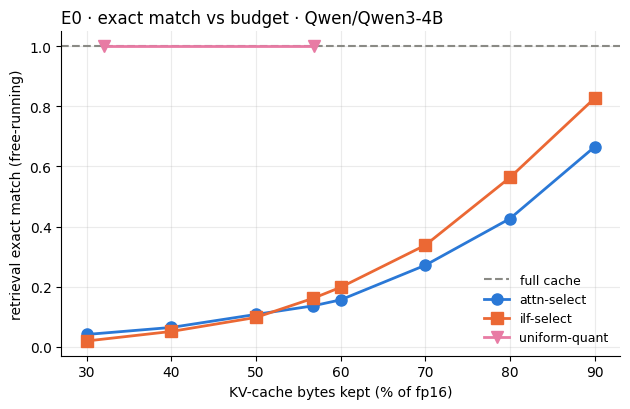

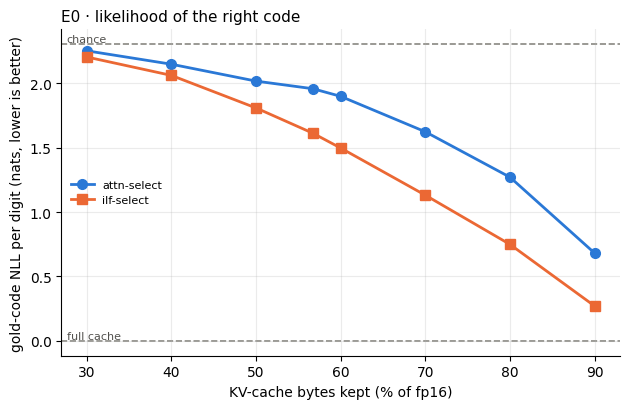

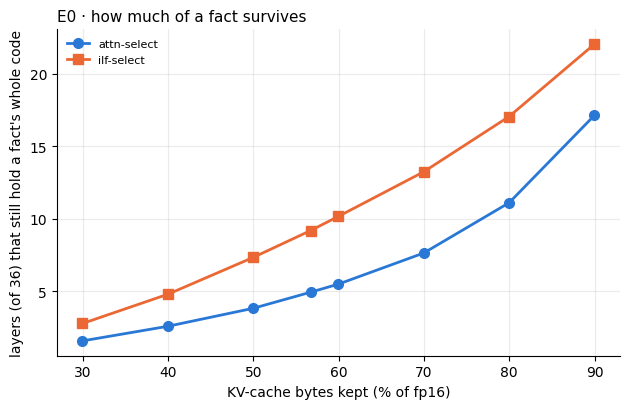

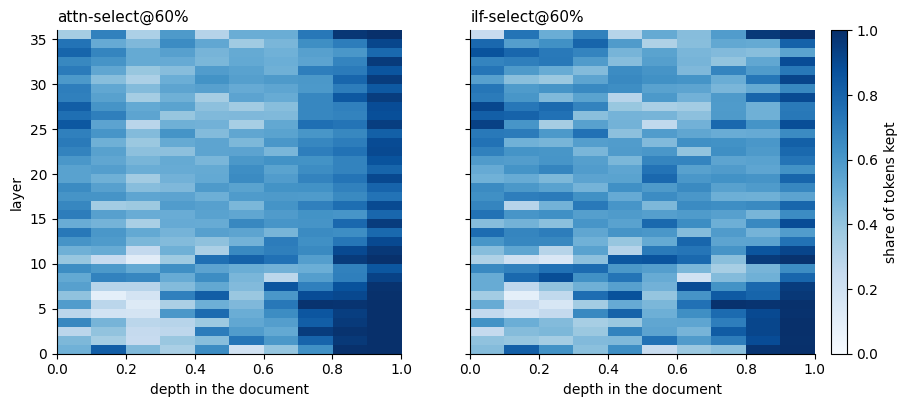

Saved /content/drive/MyDrive/kv_cache_results2_l4/Qwen__Qwen3-4B/e0_paired_ilf_vs_attention.csv


,a,b,metric,n,mean_a,mean_b,diff_b_minus_a,ci_lo,ci_hi,a_better,b_better
0,attn-select@30%,ilf-select@30%,correct,600,0.042,0.020,-0.022,-0.032,-0.010,20,7
1,attn-select@30%,ilf-select@30%,tf_exact,600,0.043,0.027,-0.017,-0.028,-0.003,19,9
2,attn-select@30%,ilf-select@30%,gold_nll,600,2.251,2.203,-0.048,-0.081,-0.013,371,229
3,attn-select@40%,ilf-select@40%,correct,600,0.065,0.052,-0.013,-0.030,0.005,19,11
4,attn-select@40%,ilf-select@40%,tf_exact,600,0.070,0.060,-0.010,-0.027,0.008,21,15
5,attn-select@40%,ilf-select@40%,gold_nll,600,2.147,2.060,-0.087,-0.137,-0.041,380,220
6,attn-select@50%,ilf-select@50%,correct,600,0.108,0.098,-0.010,-0.038,0.020,27,21
7,attn-select@50%,ilf-select@50%,tf_exact,600,0.117,0.115,-0.002,-0.030,0.028,29,28
8,attn-select@50%,ilf-select@50%,gold_nll,600,2.016,1.808,-0.208,-0.294,-0.122,393,207
9,attn-select@60%,ilf-select@60%,correct,600,0.157,0.198,0.042,0.008,0.082,31,56


full-cache tf-exact 1.000; attention selection is in the 20-80% band at budgets [0.7, 0.8, 0.9]
PROBE_BUDGETS = [0.7, 0.9]
===== e0 finished in 88.6 min =====


In [ ]:
if RUN_E0:
    exp_start("e0")
    e0_budgets = [*KEEP_GRID, "int8"]
    e0_arms = reference_arms() + [Arm(make_config(f"{fam}@{budget_tag(b)}", "select", b, lam))
                                  for b in e0_budgets for fam, lam in (("attn-select", 0.0), ("ilf-select", LAMBDA))]
    e0_retention = {}
    e0_raw = run_arms(model, tokenizer, e0_arms, PRIMARY, generate=True, retention=e0_retention, store="e0")
    save_table(e0_raw, MODEL_ID, "e0_budget_sweep_raw")
    e0 = summarize_arms(e0_raw)
    save_table(e0, MODEL_ID, "e0_budget_sweep")
    display(e0[["method", "kv_bytes_pct", "correct", "digit_acc", "tf_exact", "gold_nll", "needle_kept_frac",
                "code_layers_full", "mean_layer_jaccard"]].round(3))

    tradeoff_plot(e0, "correct", "retrieval exact match (free-running)", f"E0 · exact match vs budget · {MODEL_ID}",
                  EXP_OUT / "e0_exact.png")
    e0_sel = e0[e0["kind"] == "select"]
    series_plot(e0_sel, "kv_bytes_pct", "gold_nll", "family", "KV-cache bytes kept (% of fp16)",
                "gold-code NLL per digit (nats, lower is better)", "E0 · likelihood of the right code", "e0_gold_nll",
                refs=[(CHANCE_NLL, "chance"), (full_value(e0, "gold_nll"), "full cache")])
    series_plot(e0_sel, "kv_bytes_pct", "code_layers_full", "family", "KV-cache bytes kept (% of fp16)",
                f"layers (of {N_LAYERS}) that still hold a fact's whole code", "E0 · how much of a fact survives",
                "e0_code_layers")

    # Where in the document does each layer keep tokens? (middle budget of the grid)
    mid = budget_tag(KEEP_GRID[len(KEEP_GRID) // 2])
    fig, axes = panels(2, width=5.2)
    for ax, fam in zip(axes, ("attn-select", "ilf-select")):
        heat = torch.stack(e0_retention[f"{fam}@{mid}"]).mean(0).numpy()
        im = ax.imshow(heat, aspect="auto", origin="lower", cmap="Blues", vmin=0, vmax=1,
                       extent=(0, 1, 0, N_LAYERS))
        style_axis(ax, "depth in the document", "layer" if ax is axes[0] else "", f"{fam}@{mid}", legend=False)
        ax.grid(False)
    fig.colorbar(im, ax=axes, label="share of tokens kept", fraction=0.04, pad=0.02)
    fig.savefig(EXP_OUT / "e0_retention_by_depth.png", dpi=150, bbox_inches="tight")
    plt.show()

    # Paired comparison at every budget: ILF minus attention on the same questions.
    e0_paired = pd.DataFrame([paired_compare(e0_raw, f"attn-select@{budget_tag(b)}", f"ilf-select@{budget_tag(b)}", m)
                              for b in e0_budgets for m in ("correct", "tf_exact", "gold_nll")])
    save_table(e0_paired, MODEL_ID, "e0_paired_ilf_vs_attention")
    display(e0_paired.round(3))

    # Regression against the first run (documents 0-9, free-running exact match).
    if MODEL_ID == "Qwen/Qwen2.5-0.5B" and HAYSTACK == "repeat" and PRESET == "full":
        first_ten = e0_raw[e0_raw["doc"] < 10].groupby("method")["correct"].mean()
        for name, old in (("full", 0.905), ("quant-int4", 0.835), ("attn-select@int8", 0.150), ("ilf-select@int8", 0.075)):
            print(f"regression {name:>18}: now {first_ten[name]:.3f}, first run {old:.3f}")

    # Budgets where plain attention selection is neither at the floor nor at the ceiling.
    full_acc = full_value(e0, "tf_exact")
    grid = e0[(e0["family"] == "attn-select") & (e0["budget"] != "int8")].assign(b=lambda t: t["budget"].astype(float))
    usable = [float(b) for b in grid[(grid["tf_exact"] > 0.2 * full_acc) & (grid["tf_exact"] < 0.8 * full_acc)]["b"]]
    print(f"full-cache tf-exact {full_acc:.3f}; attention selection is in the 20-80% band at budgets {usable}")
    if not usable:  # nothing inside the band: take the budget closest to half of the full-cache accuracy
        usable = [float(grid.loc[(grid["tf_exact"] - 0.5 * full_acc).abs().idxmin(), "b"])]
        print(f"no grid budget falls in the band (widen KEEP_GRID); using the closest one, {usable}")
    suggested = sorted({min(usable), max(usable)})
    if AUTO_PROBE_BUDGETS:
        PROBE_BUDGETS = suggested
    print("PROBE_BUDGETS =", PROBE_BUDGETS)
    update_manifest(probe_budgets=PROBE_BUDGETS)
    exp_end("e0")

In [ ]:
# Probe budgets for E2, E3 and E6 when E0 is not run in this session: reuse what an earlier E0 chose.
if not RUN_E0 and AUTO_PROBE_BUDGETS and read_manifest().get("probe_budgets"):
    PROBE_BUDGETS = read_manifest()["probe_budgets"]
print("PROBE_BUDGETS =", PROBE_BUDGETS)

PROBE_BUDGETS = [0.7, 0.9]


## 11. E5 · Where should the bytes go? Fewer tokens at high precision or more at low
A fixed byte budget is split over precision tiers (`tier_split` = share of the budget for 16 / 8 / 4-bit
tokens), from "few tokens at 16 bits" to "as many tokens as possible at 4 bits", for four rankings: plain
attention, ILF, and two random rankings (shared across layers, independent per layer). If the random rankings
match the score-based ones, the scores carry no information about which tokens deserve bits. Uniform 8 / 4 /
2-bit quantization (nothing evicted) is the reference. Plots use per-digit accuracy and gold NLL: exact match
sits near 0 for every evicting arm.

===== e5 started 2026-11-18T07:55:39+00:00 =====
                          full [window]: tf-exact 1.000  gold NLL 0.00  needle kept 1.00  KV 100.0%  (64 s, ~67 min left)
                    quant-int8 [window]: tf-exact 1.000  gold NLL 0.00  needle kept 1.00  KV 56.9%  (68 s, ~68 min left)
                    quant-int4 [window]: tf-exact 1.000  gold NLL 0.00  needle kept 1.00  KV 32.1%  (70 s, ~68 min left)
                    quant-int2 [window]: tf-exact 0.990  gold NLL 0.01  needle kept 1.00  KV 19.7%  (72 s, ~68 min left)
     attention/16-bit only@10% [window]: tf-exact 0.002  gold NLL 2.54  needle kept 0.06  KV 10.0%  (59 s, ~65 min left)
           ilf/16-bit only@10% [window]: tf-exact 0.000  gold NLL 2.58  needle kept 0.06  KV 10.0%  (60 s, ~63 min left)
 random-shared/16-bit only@10% [window]: tf-exact 0.002  gold NLL 2.63  needle kept 0.09  KV 10.0%  (60 s, ~61 min left)
random-per-layer/16-bit only@10% [window]: tf-exact 0.000  gold NLL 2.34  needle kept 0.09  KV 10.0%  (

,method,kv_bytes_pct,tf_exact,tf_digit_acc,gold_nll
0,full,100.000,1.00,1.000,0.000
1,quant-int8,56.867,1.00,1.000,0.000
2,quant-int4,32.082,1.00,1.000,0.000
3,quant-int2,19.690,0.99,0.998,0.014


tokens_retained_frac


ranking                        attention    ilf  random-shared  \
budget split                                                     
0.1    16-bit only                 0.100  0.100          0.100   
       16/8/4 thirds               0.188  0.188          0.188   
       8-bit only                  0.169  0.169          0.169   
       10% 16-bit, rest 4-bit      0.276  0.276          0.276   
       4-bit only                  0.296  0.296          0.296   
0.2    16-bit only                 0.200  0.200          0.200   
       16/8/4 thirds               0.387  0.387          0.387   
       8-bit only                  0.347  0.347          0.347   
       10% 16-bit, rest 4-bit      0.574  0.574          0.574   
       4-bit only                  0.616  0.616          0.616   
int4   16-bit only                 0.320  0.320          0.320   
       16/8/4 thirds               0.626  0.626          0.626   
       8-bit only                  0.560  0.560          0.560   
       10% 16-bit, rest 4-bit      0.932  0.932          0.932   
       4-bit only                  1.000  1.000          1.000   

ranking                        random-per-layer  
budget split                                     
0.1    16-bit only                        0.100  
       16/8/4 thirds                      0.188  
       8-bit only                         0.169  
       10% 16-bit, rest 4-bit             0.276  
       4-bit only                         0.296  
0.2    16-bit only                        0.200  
       16/8/4 thirds                      0.387  
       8-bit only                         0.347  
       10% 16-bit, rest 4-bit             0.574  
       4-bit only                         0.616  
int4   16-bit only                        0.320  
       16/8/4 thirds                      0.626  
       8-bit only                         0.560  
       10% 16-bit, rest 4-bit             0.932  
       4-bit only                         1.000

tf_digit_acc


ranking                        attention    ilf  random-shared  \
budget split                                                     
0.1    16-bit only                 0.104  0.107          0.143   
       16/8/4 thirds               0.140  0.161          0.207   
       8-bit only                  0.135  0.145          0.189   
       10% 16-bit, rest 4-bit      0.182  0.213          0.285   
       4-bit only                  0.190  0.228          0.299   
0.2    16-bit only                 0.147  0.170          0.223   
       16/8/4 thirds               0.243  0.307          0.393   
       8-bit only                  0.222  0.273          0.346   
       10% 16-bit, rest 4-bit      0.357  0.549          0.593   
       4-bit only                  0.403  0.607          0.639   
int4   16-bit only                 0.207  0.254          0.331   
       16/8/4 thirds               0.418  0.622          0.654   
       8-bit only                  0.350  0.525          0.577   
       10% 16-bit, rest 4-bit      0.921  0.979          0.943   
       4-bit only                  1.000  1.000          1.000   

ranking                        random-per-layer  
budget split                                     
0.1    16-bit only                        0.168  
       16/8/4 thirds                      0.255  
       8-bit only                         0.235  
       10% 16-bit, rest 4-bit             0.409  
       4-bit only                         0.458  
0.2    16-bit only                        0.271  
       16/8/4 thirds                      0.664  
       8-bit only                         0.582  
       10% 16-bit, rest 4-bit             0.921  
       4-bit only                         0.952  
int4   16-bit only                        0.526  
       16/8/4 thirds                      0.959  
       8-bit only                         0.910  
       10% 16-bit, rest 4-bit             1.000  
       4-bit only                         1.000

gold_nll


ranking                        attention    ilf  random-shared  \
budget split                                                     
0.1    16-bit only                 2.541  2.577          2.635   
       16/8/4 thirds               2.405  2.364          2.657   
       8-bit only                  2.429  2.446          2.688   
       10% 16-bit, rest 4-bit      2.273  2.237          2.663   
       4-bit only                  2.253  2.219          2.711   
0.2    16-bit only                 2.386  2.359          2.660   
       16/8/4 thirds               2.158  2.087          2.656   
       8-bit only                  2.195  2.169          2.677   
       10% 16-bit, rest 4-bit      1.958  1.583          2.418   
       4-bit only                  1.857  1.436          2.307   
int4   16-bit only                 2.229  2.178          2.703   
       16/8/4 thirds               1.846  1.405          2.249   
       8-bit only                  1.949  1.626          2.437   
       10% 16-bit, rest 4-bit      0.429  0.151          0.576   
       4-bit only                  0.000  0.000          0.000   

ranking                        random-per-layer  
budget split                                     
0.1    16-bit only                        2.339  
       16/8/4 thirds                      2.181  
       8-bit only                         2.201  
       10% 16-bit, rest 4-bit             1.860  
       4-bit only                         1.774  
0.2    16-bit only                        2.134  
       16/8/4 thirds                      1.293  
       8-bit only                         1.508  
       10% 16-bit, rest 4-bit             0.411  
       4-bit only                         0.281  
int4   16-bit only                        1.626  
       16/8/4 thirds                      0.244  
       8-bit only                         0.444  
       10% 16-bit, rest 4-bit             0.005  
       4-bit only                         0.000

Saved /content/drive/MyDrive/kv_cache_results2_l4/Qwen__Qwen3-4B/e5_paired_vs_attention.csv


,budget,split,a,b,metric,n,mean_a,mean_b,diff_b_minus_a,ci_lo,ci_hi,a_better,b_better
0,0.1,16-bit only,attention/16-bit only@10%,ilf/16-bit only@10%,tf_digit_acc,600,0.104,0.107,0.003,-0.008,0.013,81,93
2,0.1,16-bit only,attention/16-bit only@10%,random-shared/16-bit only@10%,tf_digit_acc,600,0.104,0.143,0.039,0.026,0.051,99,201
4,0.1,16-bit only,attention/16-bit only@10%,random-per-layer/16-bit only@10%,tf_digit_acc,600,0.104,0.168,0.064,0.045,0.082,93,237
6,0.1,16/8/4 thirds,attention/16/8/4 thirds@10%,ilf/16/8/4 thirds@10%,tf_digit_acc,600,0.140,0.161,0.021,0.006,0.037,100,156
8,0.1,16/8/4 thirds,attention/16/8/4 thirds@10%,random-shared/16/8/4 thirds@10%,tf_digit_acc,600,0.140,0.207,0.067,0.049,0.087,111,264
10,0.1,16/8/4 thirds,attention/16/8/4 thirds@10%,random-per-layer/16/8/4 thirds@10%,tf_digit_acc,600,0.140,0.255,0.115,0.095,0.133,95,312
12,0.1,8-bit only,attention/8-bit only@10%,ilf/8-bit only@10%,tf_digit_acc,600,0.135,0.145,0.011,-0.003,0.025,100,127
14,0.1,8-bit only,attention/8-bit only@10%,random-shared/8-bit only@10%,tf_digit_acc,600,0.135,0.189,0.054,0.036,0.072,109,242
16,0.1,8-bit only,attention/8-bit only@10%,random-per-layer/8-bit only@10%,tf_digit_acc,600,0.135,0.235,0.100,0.083,0.117,97,294
18,0.1,"10% 16-bit, rest 4-bit","attention/10% 16-bit, rest 4-bit@10%","ilf/10% 16-bit, rest 4-bit@10%",tf_digit_acc,600,0.182,0.213,0.030,0.017,0.044,122,173


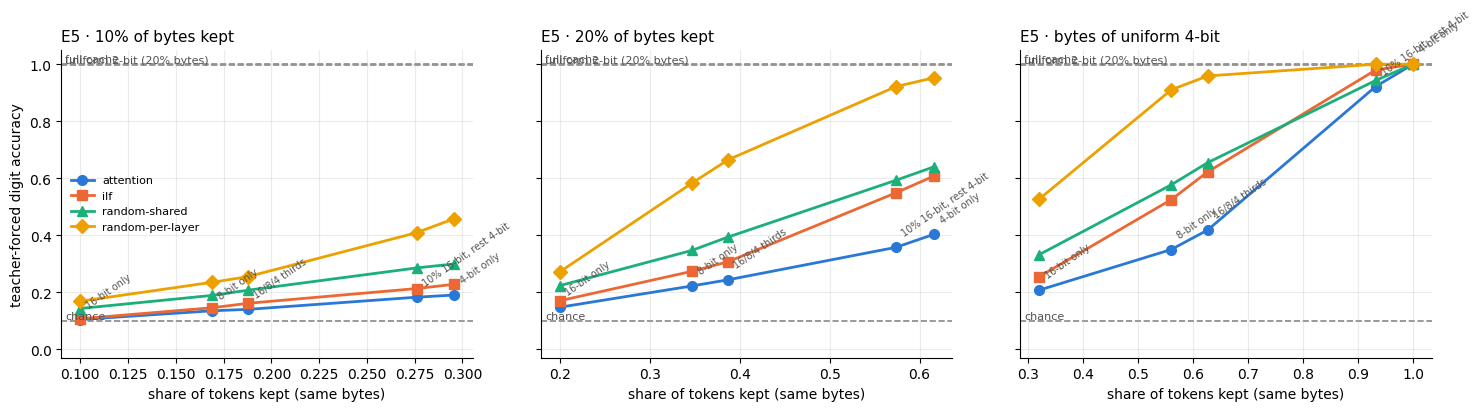

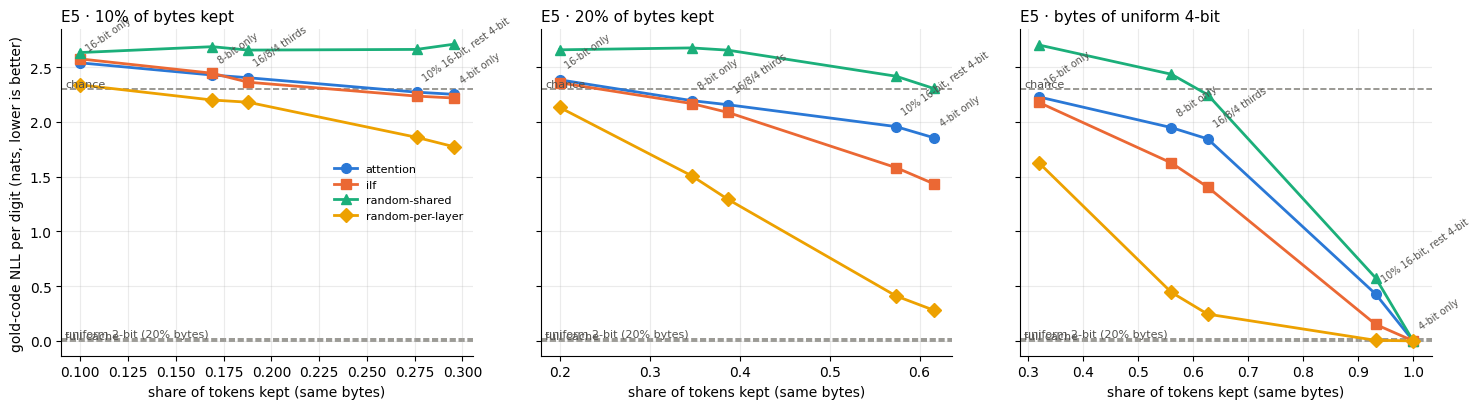

===== e5 finished in 72.5 min =====


In [ ]:
E5_SPLITS = {"16-bit only": (1, 0, 0), "16/8/4 thirds": (1 / 3, 1 / 3, 1 / 3), "8-bit only": (0, 1, 0),
             "10% 16-bit, rest 4-bit": (0.1, 0, 0.9), "4-bit only": (0, 0, 1)}
E5_RANKINGS = {"attention": {}, "ilf": {"lam": LAMBDA}, "random-shared": {"score_mode": "random_shared"},
               "random-per-layer": {"score_mode": "random_layer"}}

if RUN_E5:
    exp_start("e5")
    e5_arms = reference_arms({"ranking": "uniform", "split": "uniform"}, bits=(8, 4, 2))
    e5_arms += [Arm(make_config(f"{rank}/{split}@{budget_tag(b)}", "mixed", b, tier_split=shares, **kw),
                    tags={"ranking": rank, "split": split})
                for b in E5_BUDGETS for split, shares in E5_SPLITS.items() for rank, kw in E5_RANKINGS.items()]
    e5_raw = run_arms(model, tokenizer, e5_arms, PRIMARY, generate=EXP_GENERATE, store="e5")
    save_table(e5_raw, MODEL_ID, "e5_tier_split_raw")
    e5 = add_eviction_ratio(summarize_arms(e5_raw, by=["ranking", "split"]))
    save_table(e5, MODEL_ID, "e5_tier_split")
    display(e5[e5["ranking"] == "uniform"][["method", "kv_bytes_pct", "tf_exact", "tf_digit_acc", "gold_nll"]].round(3))
    e5_mixed = e5[e5["kind"] == "mixed"]
    for metric in ("tokens_retained_frac", "tf_digit_acc", "gold_nll"):
        print(metric)
        display(e5_mixed.pivot_table(index=["budget", "split"], columns="ranking", values=metric, sort=False).round(3))

    # Every ranking against attention ranking, same split and budget, same questions.
    e5_paired = pd.DataFrame([row for b in E5_BUDGETS for split in E5_SPLITS
                              for row in paired_vs(e5_raw, f"attention/{split}@{budget_tag(b)}",
                                                   [f"{r}/{split}@{budget_tag(b)}" for r in E5_RANKINGS],
                                                   extra={"budget": str(b), "split": split})])
    save_table(e5_paired, MODEL_ID, "e5_paired_vs_attention")
    display(e5_paired[e5_paired["metric"] == "tf_digit_acc"].round(3))

    uniform = e5[e5["ranking"] == "uniform"].set_index("method")
    for metric, ylabel, unit in (("tf_digit_acc", "teacher-forced digit accuracy", True),
                                 ("gold_nll", "gold-code NLL per digit (nats, lower is better)", False)):
        refs = [(uniform.loc["full", metric], "full cache")]
        refs += [(0.1, "chance")] if metric == "tf_digit_acc" else [(CHANCE_NLL, "chance")]
        if "quant-int2" in uniform.index:
            refs += [(uniform.loc["quant-int2", metric], f"uniform 2-bit ({uniform.loc['quant-int2', 'kv_bytes_pct']:.0f}% bytes)")]
        fig, axes = panels(len(E5_BUDGETS), width=5.0)
        for ax, b in zip(axes, E5_BUDGETS):
            part = e5_mixed[e5_mixed["budget"] == str(b)]
            draw_series(ax, part, "tokens_retained_frac", metric, "ranking", order=list(E5_RANKINGS), refs=refs)
            for _, r in part[part["ranking"] == "attention"].iterrows():  # name the splits once, on one series
                ax.annotate(r["split"], (r["tokens_retained_frac"], r[metric]), xytext=(3, 7), rotation=35,
                            textcoords="offset points", ha="left", va="bottom", fontsize=7, color=INK_SECONDARY)
            style_axis(ax, "share of tokens kept (same bytes)", ylabel if ax is axes[0] else "",
                       f"E5 · {budget_title(b)}", legend=ax is axes[0], unit=unit)
        save_show(fig, f"e5_tier_split_{metric}")
    exp_end("e5")

## 12. E2 · Consistency sweep: from ILF to one shared kept set
The corrected λ sweep. At each probe budget, selection methods are lined up from most diverse to most
consistent across layers, at identical bytes:
* **ILF** with λ = 4, 1, 0.25, plus two repairs of its formula: `ilf-gated` (no boost for tokens that no
  layer would keep, which otherwise get the largest boost) and a tighter τ.
* **plain attention**, each layer on its own (the baseline).
* **mix α**: `(1−α)·rank_l + α·mean-rank over layers`; α = 1 keeps the same tokens in every layer.
* **lf**: `a·(1 + λ·log(1+d_i))`, the opposite of ILF, boosting tokens that many layers want.
* **random controls**: one random set shared by all layers vs an independent random set per layer. These two
  keep the same number of tokens and differ only in cross-layer agreement.

The figure plots each arm's retrieval against `mean_layer_jaccard`. H1 predicts a rising trend.

===== e2 started 2026-11-18T09:08:07+00:00 =====
                          full [window]: tf-exact 1.000  gold NLL 0.00  needle kept 1.00  KV 100.0%  (64 s, ~34 min left)
                   ilf λ=4@70% [window]: tf-exact 0.742  gold NLL 0.42  needle kept 0.74  KV 70.0%  (60 s, ~32 min left)
                   ilf λ=1@70% [window]: tf-exact 0.393  gold NLL 1.13  needle kept 0.66  KV 70.0%  (60 s, ~31 min left)
                ilf λ=0.25@70% [window]: tf-exact 0.283  gold NLL 1.55  needle kept 0.61  KV 70.0%  (60 s, ~30 min left)
             ilf-gated λ=4@70% [window]: tf-exact 0.682  gold NLL 0.57  needle kept 0.74  KV 70.0%  (60 s, ~28 min left)
             ilf-gated λ=1@70% [window]: tf-exact 0.372  gold NLL 1.21  needle kept 0.66  KV 70.0%  (60 s, ~27 min left)
           ilf-tight-τ λ=1@70% [window]: tf-exact 0.387  gold NLL 1.26  needle kept 0.67  KV 70.0%  (60 s, ~26 min left)
                 attention@70% [window]: tf-exact 0.278  gold NLL 1.62  needle kept 0.59  KV 70.0%  (60

,method,group,mean_layer_jaccard,unique_positions_frac,tf_exact,tf_digit_acc,gold_nll,code_layers_full
0,full,reference,1.000,1.000,1.000,1.000,0.000,36.000
1,ilf λ=4@70%,ILF (more diverse),0.588,1.000,0.742,0.922,0.420,22.015
2,ilf λ=1@70%,ILF (more diverse),0.572,1.000,0.393,0.718,1.131,13.250
3,ilf λ=0.25@70%,ILF (more diverse),0.634,1.000,0.283,0.533,1.552,9.195
4,ilf-gated λ=4@70%,ILF (more diverse),0.590,0.995,0.682,0.908,0.575,19.647
5,ilf-gated λ=1@70%,ILF (more diverse),0.575,0.995,0.372,0.702,1.206,12.387
6,ilf-tight-τ λ=1@70%,ILF (more diverse),0.574,1.000,0.387,0.706,1.263,12.288
7,attention@70%,per-layer attention,0.686,0.995,0.278,0.504,1.623,7.643
8,mix α=0.25@70%,more consistent,0.728,0.985,0.267,0.482,1.713,6.783
9,mix α=0.5@70%,more consistent,0.792,0.952,0.240,0.452,1.853,5.817


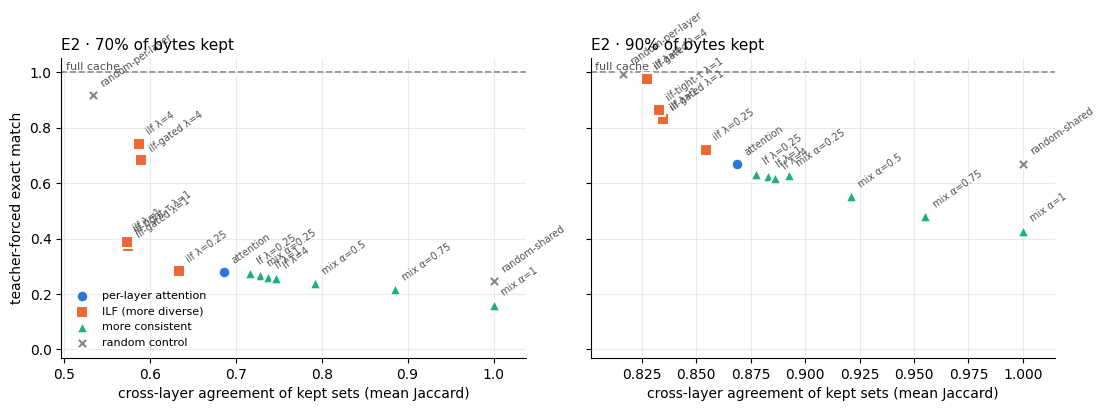

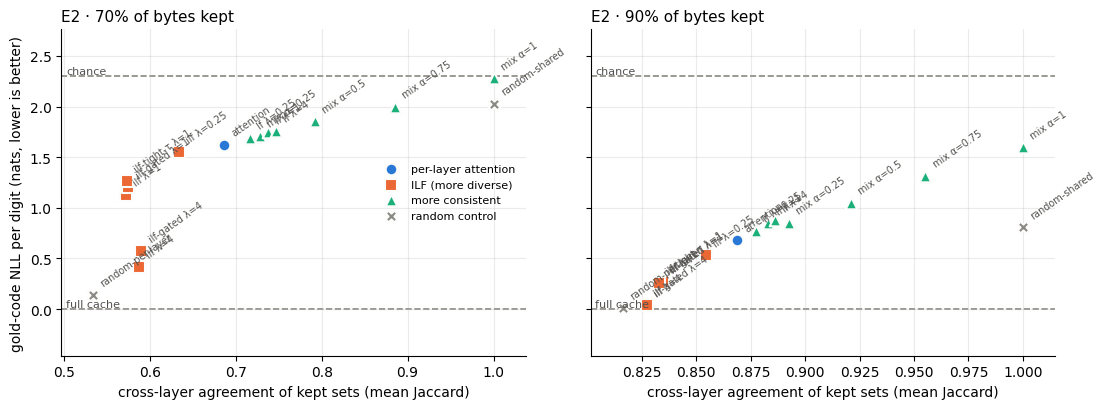

Saved /content/drive/MyDrive/kv_cache_results2_l4/Qwen__Qwen3-4B/e2_paired_vs_attention.csv


,budget,a,b,metric,n,mean_a,mean_b,diff_b_minus_a,ci_lo,ci_hi,a_better,b_better
1,0.7,attention@70%,ilf λ=4@70%,gold_nll,600,1.623,0.420,-1.203,-1.355,-1.039,429,171
3,0.7,attention@70%,ilf λ=1@70%,gold_nll,600,1.623,1.131,-0.492,-0.590,-0.393,392,208
5,0.7,attention@70%,ilf λ=0.25@70%,gold_nll,600,1.623,1.552,-0.071,-0.121,-0.020,355,245
7,0.7,attention@70%,ilf-gated λ=4@70%,gold_nll,600,1.623,0.575,-1.048,-1.184,-0.901,407,193
9,0.7,attention@70%,ilf-gated λ=1@70%,gold_nll,600,1.623,1.206,-0.417,-0.510,-0.325,375,225
11,0.7,attention@70%,ilf-tight-τ λ=1@70%,gold_nll,600,1.623,1.263,-0.359,-0.459,-0.262,364,236
13,0.7,attention@70%,mix α=0.25@70%,gold_nll,600,1.623,1.713,0.091,0.053,0.130,215,384
15,0.7,attention@70%,mix α=0.5@70%,gold_nll,600,1.623,1.853,0.231,0.159,0.302,199,400
17,0.7,attention@70%,mix α=0.75@70%,gold_nll,600,1.623,1.997,0.374,0.288,0.460,175,425
19,0.7,attention@70%,mix α=1@70%,gold_nll,600,1.623,2.280,0.657,0.530,0.782,165,435


===== e2 finished in 34.0 min =====


In [ ]:
E2_GROUPS = {"per-layer attention": (SERIES_COLORS[0], "o"), "ILF (more diverse)": (SERIES_COLORS[1], "s"),
             "more consistent": (SERIES_COLORS[2], "^"), "random control": (INK_MUTED, "X")}


def e2_arms_at(b):
    def arm(label, group, lam=0.0, **kw):
        return Arm(select_cfg(label, b, lam, **kw), tags={"arm": label, "group": group})
    diverse, consistent = "ILF (more diverse)", "more consistent"
    return ([arm(f"ilf λ={lam:g}", diverse, lam) for lam in (4.0, 1.0, 0.25)]
            + [arm(f"ilf-gated λ={lam:g}", diverse, lam, score_mode="ilf_gated") for lam in (4.0, 1.0)]
            + [arm("ilf-tight-τ λ=1", diverse, 1.0, tau_quantile=1 - b / 2)]
            + [arm("attention", "per-layer attention")]
            + [arm(f"mix α={a:g}", consistent, score_mode="mix", layer_mix=a) for a in (0.25, 0.5, 0.75, 1.0)]
            + [arm(f"lf λ={lam:g}", consistent, lam, score_mode="lf") for lam in (0.25, 1.0, 4.0)]
            + [arm("random-shared", "random control", score_mode="random_shared"),
               arm("random-per-layer", "random control", score_mode="random_layer")])


def scatter_by_group(ax, df, x, y):
    for group, (color, marker) in E2_GROUPS.items():
        part = df[df["group"] == group]
        ax.scatter(part[x], part[y], s=70, color=color, marker=marker, edgecolors=SURFACE, linewidths=1.5,
                   label=group, zorder=4 if group == "per-layer attention" else 3)
        for _, r in part.iterrows():  # every point is named; the table above carries the exact values
            ax.annotate(r["arm"], (r[x], r[y]), xytext=(4, 5), textcoords="offset points", fontsize=7,
                        color=INK_SECONDARY, rotation=35, ha="left", va="bottom")


if RUN_E2:
    exp_start("e2")
    e2_arms = [Arm(make_config("full", "full"), tags={"arm": "full", "group": "reference"})]
    for b in PROBE_BUDGETS:
        e2_arms += e2_arms_at(b)
    e2_raw = run_arms(model, tokenizer, e2_arms, PRIMARY, generate=EXP_GENERATE, store="e2")
    save_table(e2_raw, MODEL_ID, "e2_consistency_raw")
    e2 = summarize_arms(e2_raw, keys=["method", "arm", "group", "budget", "kind"])
    save_table(e2, MODEL_ID, "e2_consistency")
    display(e2[["method", "group", "mean_layer_jaccard", "unique_positions_frac", "tf_exact", "tf_digit_acc", "gold_nll",
                "code_layers_full"]].round(3))

    for metric, ylabel, refs in (
            ("tf_exact", "teacher-forced exact match", [(full_value(e2, "tf_exact"), "full cache")]),
            ("gold_nll", "gold-code NLL per digit (nats, lower is better)",
             [(CHANCE_NLL, "chance"), (full_value(e2, "gold_nll"), "full cache")])):
        fig, axes = panels(len(PROBE_BUDGETS))
        for ax, b in zip(axes, PROBE_BUDGETS):
            scatter_by_group(ax, e2[e2["budget"] == str(b)], "mean_layer_jaccard", metric)
            ax.margins(x=0.08, y=0.2)  # room for the point labels
            draw_refs(ax, refs)
            style_axis(ax, "cross-layer agreement of kept sets (mean Jaccard)", ylabel if ax is axes[0] else "",
                       f"E2 · {budget_title(b)}", legend=ax is axes[0], unit=metric == "tf_exact")
        save_show(fig, f"e2_consistency_{metric}")

    # Every arm against plain attention on the same questions.
    e2_paired = pd.DataFrame([
        {"budget": b, **paired_compare(e2_raw, f"attention@{budget_tag(b)}", arm.cfg.name, metric)}
        for b in PROBE_BUDGETS for arm in e2_arms_at(b) if arm.tags["arm"] != "attention"
        for metric in ("tf_exact", "gold_nll")])
    save_table(e2_paired, MODEL_ID, "e2_paired_vs_attention")
    display(e2_paired[e2_paired["metric"] == "gold_nll"].round(3))
    exp_end("e2")

## 13. E1 · Layer coverage: is a token kept in only a few layers worth anything?
ILF trades *layers per token* for *more distinct tokens*. This experiment measures what that trade
costs, using the known positions of the facts (an oracle, so not a compression method):
* **Knock-out.** The cache is left complete except that every fact sentence is evicted from all but `m`
  layers. The surviving layers are the lowest `m`, the highest `m`, `m` random layers per fact, or `m`
  random layers per token (the closest picture of what ILF produces).
* **Single-layer scan.** The facts are evicted from one layer at a time, which shows which layers carry retrieval.
* **Oracle-keep.** Selection at 10% and 20% bytes with the fact tokens ranked first in every layer. This is
  the ceiling for any query-agnostic token selector at that budget; the gap to plain attention selection is
  what a better scoring signal could recover.

If accuracy needs the fact in most layers, counting distinct positions kept in *any* layer
(`unique_positions`) measures the wrong thing, and the useful statistic is layers per token.


`E1_LAYER_STRIDE = 2` scans every second layer only, which halves the single-layer block.

===== e1 started 2026-11-18T09:42:04+00:00 =====
                          full [window]: tf-exact 1.000  gold NLL 0.00  needle kept 1.00  KV 100.0%  (64 s, ~85 min left)
         knockout-lowest-m0-s0 [window]: tf-exact 0.000  gold NLL 2.72  needle kept 0.00  KV 91.6%  (63 s, ~83 min left)
         knockout-lowest-m3-s0 [window]: tf-exact 0.000  gold NLL 2.73  needle kept 0.08  KV 92.3%  (63 s, ~82 min left)
         knockout-lowest-m6-s0 [window]: tf-exact 0.000  gold NLL 2.71  needle kept 0.17  KV 93.0%  (63 s, ~81 min left)
        knockout-lowest-m12-s0 [window]: tf-exact 0.000  gold NLL 2.75  needle kept 0.33  KV 94.4%  (63 s, ~80 min left)
        knockout-lowest-m18-s0 [window]: tf-exact 0.000  gold NLL 2.62  needle kept 0.50  KV 95.8%  (64 s, ~79 min left)
        knockout-lowest-m24-s0 [window]: tf-exact 0.950  gold NLL 0.06  needle kept 0.67  KV 97.2%  (64 s, ~78 min left)
        knockout-lowest-m30-s0 [window]: tf-exact 1.000  gold NLL 0.00  needle kept 0.83  KV 98.6%  (64

scheme,highest,lowest,random_fact,random_token
layers_kept,,,,
0.0,0.000,0.00,0.000,0.000
3.0,0.000,0.00,0.001,0.000
6.0,0.000,0.00,0.005,0.002
12.0,0.000,0.00,0.074,0.093
18.0,0.825,0.00,0.303,0.533
24.0,0.757,0.95,0.626,0.900
30.0,1.000,1.00,0.890,0.990
36.0,1.000,1.00,1.000,1.000


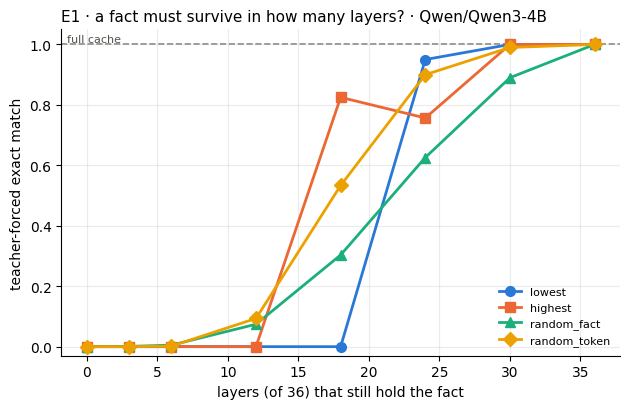

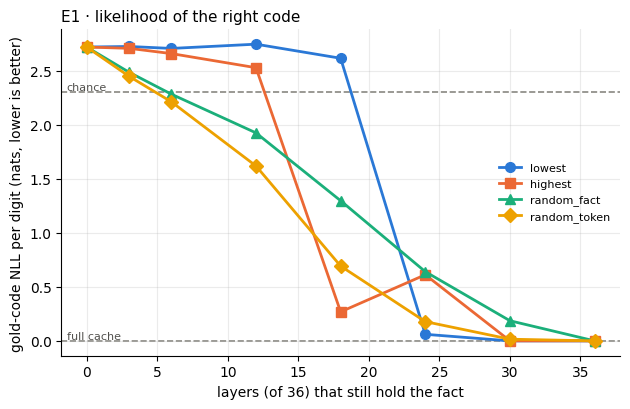

Saved /content/drive/MyDrive/kv_cache_results2_l4/Qwen__Qwen3-4B/e1_single_layer.csv


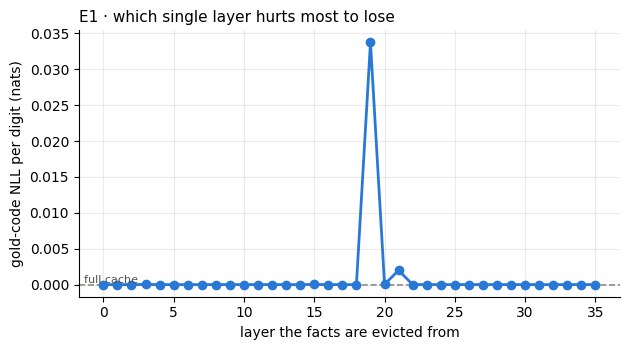

Saved /content/drive/MyDrive/kv_cache_results2_l4/Qwen__Qwen3-4B/e1_oracle_keep.csv


,budget,scheme,tf_exact,tf_digit_acc,gold_nll,needle_kept_frac,kv_bytes_pct
0,0.1,plain attention,0.002,0.104,2.541,0.056,9.986
1,0.1,facts ranked first,1.000,1.000,0.000,1.000,9.986
2,0.2,plain attention,0.018,0.147,2.386,0.129,19.986
3,0.2,facts ranked first,1.000,1.000,0.000,1.000,19.986


full cache: tf-exact 1.000, gold NLL 0.00
===== e1 finished in 85.8 min =====


In [ ]:
if RUN_E1:
    exp_start("e1")
    m_grid = sorted({round(N_LAYERS * f) for f in (0, 1 / 12, 1 / 6, 1 / 3, 1 / 2, 2 / 3, 5 / 6, 1)})
    e1_arms = [Arm(make_config("full", "full"), tags={"experiment": "reference", "scheme": "full"})]
    for scheme, seeds in (("lowest", [0]), ("highest", [0]), ("random_fact", [0, 1]), ("random_token", [0])):
        for m in m_grid:
            for seed in seeds:
                e1_arms.append(Arm(make_config(f"knockout-{scheme}-m{m}-s{seed}", "full"), plan=knockout_plan(scheme, m, seed),
                                   tags={"experiment": "knockout", "scheme": scheme, "layers_kept": m, "seed": seed}))
    for layer in range(0, N_LAYERS, E1_LAYER_STRIDE):
        e1_arms.append(Arm(make_config(f"knockout-layer{layer}", "full"), plan=knockout_plan("single", layer),
                           tags={"experiment": "single_layer", "scheme": "single", "layer": layer}))
    for b in (0.1, 0.2):
        e1_arms.append(Arm(select_cfg("attn-select", b), tags={"experiment": "oracle", "scheme": "plain attention"}))
        e1_arms.append(Arm(select_cfg("oracle-keep", b), plan=protect_plan,
                           tags={"experiment": "oracle", "scheme": "facts ranked first"}))
    e1_raw = run_arms(model, tokenizer, e1_arms, PRIMARY, generate=EXP_GENERATE, store="e1")
    save_table(e1_raw, MODEL_ID, "e1_layer_coverage_raw")
    e1_full = e1_raw[e1_raw["experiment"] == "reference"]
    full_refs = lambda metric: [(e1_full[metric].astype(float).mean(), "full cache")]

    knock = summarize_arms(e1_raw[e1_raw["experiment"] == "knockout"], keys=["scheme", "layers_kept"])
    save_table(knock, MODEL_ID, "e1_knockout")
    display(knock.pivot(index="layers_kept", columns="scheme", values="tf_exact").round(3))
    series_plot(knock, "layers_kept", "tf_exact", "scheme", f"layers (of {N_LAYERS}) that still hold the fact",
                "teacher-forced exact match", f"E1 · a fact must survive in how many layers? · {MODEL_ID}",
                "e1_knockout_exact", refs=full_refs("tf_exact"), unit=True)
    series_plot(knock, "layers_kept", "gold_nll", "scheme", f"layers (of {N_LAYERS}) that still hold the fact",
                "gold-code NLL per digit (nats, lower is better)", "E1 · likelihood of the right code",
                "e1_knockout_nll", refs=[(CHANCE_NLL, "chance"), *full_refs("gold_nll")])

    scan = summarize_arms(e1_raw[e1_raw["experiment"] == "single_layer"], keys=["layer"])
    save_table(scan, MODEL_ID, "e1_single_layer")
    fig, ax = plt.subplots(figsize=(6.4, 3.6))
    ax.plot(scan["layer"], scan["gold_nll"], color=SERIES_COLORS[0], marker="o", lw=2, ms=6)
    draw_refs(ax, full_refs("gold_nll"))
    style_axis(ax, "layer the facts are evicted from", "gold-code NLL per digit (nats)",
               "E1 · which single layer hurts most to lose", legend=False)
    save_show(fig, "e1_single_layer")

    oracle = summarize_arms(e1_raw[e1_raw["experiment"] == "oracle"], keys=["budget", "scheme"])
    save_table(oracle, MODEL_ID, "e1_oracle_keep")
    display(oracle[["budget", "scheme", "tf_exact", "tf_digit_acc", "gold_nll", "needle_kept_frac", "kv_bytes_pct"]].round(3))
    print(f"full cache: tf-exact {full_refs('tf_exact')[0][0]:.3f}, gold NLL {full_refs('gold_nll')[0][0]:.2f}")
    exp_end("e1")

## 14. E3 · Scoring signal: what must the selector see?
ILF only re-weights the attention scores it is given, so this experiment varies where those scores come
from and keeps everything else fixed. The compressed cache always holds the document only; any extra
tokens are used for scoring and then dropped.

| Signal | Scores are the attention from … |
|---|---|
| `window` | the last 32 document tokens (the default in every other experiment) |
| `all_queries` | every later document token, averaged over the tokens that can see each key (H2O-style) |
| `probe` | a fixed, task-agnostic instruction appended after the document |
| `reconstruct` | the document read a second time after "Repeat the text above", max over queries. A simplified version of KVzip's query-agnostic scoring ([arXiv 2505.23416](https://arxiv.org/abs/2505.23416)), not a reimplementation |
| question (same) | the very question that is then asked: query-aware compression, not reusable |
| question (different) | a question about *another* fact: a query-aware cache reused for a new question, the case the proposal is about |

Each signal is combined with plain attention selection, ILF (λ = `LAMBDA`) and the consistent selector
(one kept set for all layers). ILF's fairest test is the "question (different)" row.

===== e3 started 2026-11-18T11:07:54+00:00 =====
                          full [window]: tf-exact 1.000  gold NLL 0.00  needle kept 1.00  KV 100.0%  (64 s, ~32 min left)
          attention/window@70% [window]: tf-exact 0.278  gold NLL 1.62  needle kept 0.59  KV 70.0%  (60 s, ~30 min left)
                ilf/window@70% [window]: tf-exact 0.393  gold NLL 1.13  needle kept 0.66  KV 70.0%  (60 s, ~29 min left)
         consistent/window@70% [window]: tf-exact 0.162  gold NLL 2.28  needle kept 0.55  KV 70.0%  (60 s, ~28 min left)
     attention/all_queries@70% [all_queries]: tf-exact 0.747  gold NLL 0.47  needle kept 0.75  KV 70.0%  (113 s, ~31 min left)
           ilf/all_queries@70% [all_queries]: tf-exact 0.583  gold NLL 0.61  needle kept 0.63  KV 70.0%  (113 s, ~33 min left)
    consistent/all_queries@70% [all_queries]: tf-exact 0.500  gold NLL 1.69  needle kept 0.76  KV 70.0%  (113 s, ~33 min left)
           attention/probe@70% [probe]: tf-exact 0.997  gold NLL 0.01  needle kept 0.

selector                     attention    ilf  consistent
budget signal                                            
0.7    all_queries               0.747  0.583       0.500
       probe                     0.997  0.998       1.000
       question (different)      1.000  1.000       1.000
       question (same)           1.000  1.000       1.000
       reconstruct               0.028  0.998       0.000
       window                    0.278  0.393       0.162
0.9    all_queries               0.998  0.993       0.887
       probe                     1.000  1.000       1.000
       question (different)      1.000  1.000       1.000
       question (same)           1.000  1.000       1.000
       reconstruct               0.485  0.998       0.032
       window                    0.668  0.830       0.428

gold_nll


selector                     attention    ilf  consistent
budget signal                                            
0.7    all_queries               0.474  0.610       1.695
       probe                     0.008  0.012       0.000
       question (different)      0.000  0.000       0.000
       question (same)           0.000  0.000       0.000
       reconstruct               1.824  0.003       2.665
       window                    1.623  1.131       2.280
0.9    all_queries               0.001  0.009       0.339
       probe                     0.000  0.000       0.000
       question (different)      0.000  0.000       0.000
       question (same)           0.000  0.000       0.000
       reconstruct               0.511  0.002       2.166
       window                    0.681  0.271       1.600

code_layers_full


selector                     attention     ilf  consistent
budget signal                                             
0.7    all_queries              17.447  19.435       17.28
       probe                    28.783  26.093       36.00
       question (different)     32.126  29.658       36.00
       question (same)          32.763  30.443       36.00
       reconstruct               7.412  22.092        0.00
       window                    7.643  13.250        5.04
0.9    all_queries              28.235  26.633       30.12
       probe                    33.415  32.475       36.00
       question (different)     34.816  34.122       36.00
       question (same)          34.797  34.357       36.00
       reconstruct              16.817  24.030        1.50
       window                   17.143  22.058       13.02

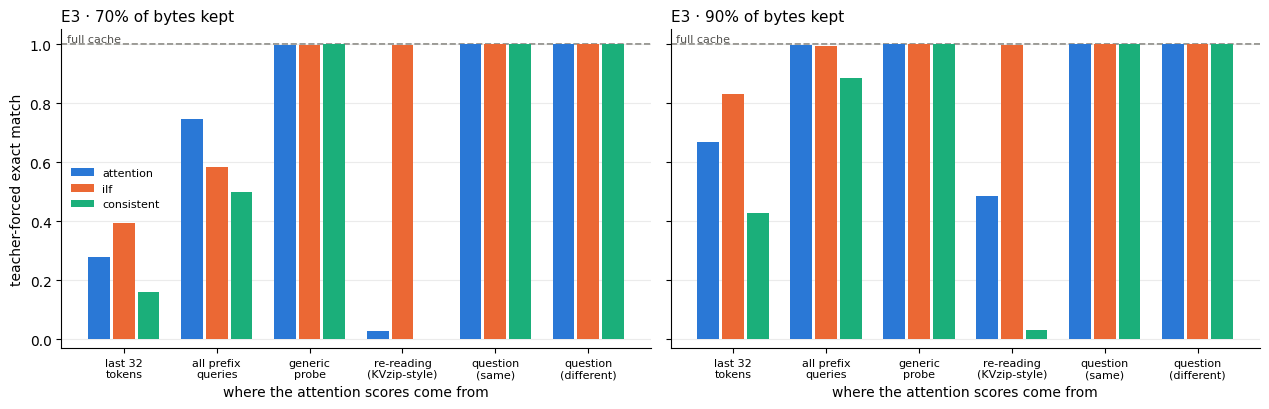

===== e3 finished in 77.0 min =====


In [ ]:
E3_SIGNAL_LABELS = {"window": "last 32\ntokens", "all_queries": "all prefix\nqueries", "probe": "generic\nprobe",
                    "reconstruct": "re-reading\n(KVzip-style)", "question (same)": "question\n(same)",
                    "question (different)": "question\n(different)"}

if RUN_E3:
    exp_start("e3")
    e3_signals = ["window", "all_queries", "probe", "reconstruct", "query"]
    longest = max(len(tokenizer(doc).input_ids) for doc, _ in PRIMARY)
    if 2 * longest + 32 > getattr(model.config, "max_position_embeddings", 0):
        e3_signals.remove("reconstruct")
        print("Skipping 'reconstruct': two copies of the document do not fit the model's context.")
    e3_selectors = {"attention": {}, "ilf": {"lam": LAMBDA}, "consistent": {"score_mode": "mix", "layer_mix": 1.0}}
    e3_arms = [Arm(make_config("full", "full"), tags={"selector": "full"})]
    e3_arms += [Arm(select_cfg(f"{sel}/{sig}", b, **kw), scoring=sig, tags={"selector": sel})
                for b in PROBE_BUDGETS for sig in e3_signals for sel, kw in e3_selectors.items()]
    e3_raw = run_arms(model, tokenizer, e3_arms, PRIMARY, generate=EXP_GENERATE, store="e3")
    e3_raw["signal"] = e3_raw["scoring"]
    e3_raw.loc[e3_raw["query_match"] == True, "signal"] = "question (same)"       # noqa: E712
    e3_raw.loc[e3_raw["query_match"] == False, "signal"] = "question (different)"  # noqa: E712
    save_table(e3_raw, MODEL_ID, "e3_scoring_signal_raw")
    e3 = summarize_arms(e3_raw, keys=["budget", "signal", "selector", "kind"])
    save_table(e3, MODEL_ID, "e3_scoring_signal")
    e3_sel = e3[e3["kind"] == "select"]
    order = [s for s in E3_SIGNAL_LABELS if s in set(e3_sel["signal"])]
    for metric in ("tf_exact", "gold_nll", "code_layers_full"):
        print(metric)
        display(e3_sel.pivot_table(index=["budget", "signal"], columns="selector", values=metric)
                .reindex(columns=list(e3_selectors)).round(3))

    fig, axes = panels(len(PROBE_BUDGETS), width=6.4)
    for ax, b in zip(axes, PROBE_BUDGETS):
        table = (e3_sel[e3_sel["budget"] == str(b)].pivot(index="signal", columns="selector", values="tf_exact")
                 .reindex(index=order, columns=list(e3_selectors)))
        table.index = [E3_SIGNAL_LABELS[s] for s in table.index]
        grouped_bars(ax, table, SERIES_COLORS, refs=[(full_value(e3, "tf_exact"), "full cache")])
        style_axis(ax, "where the attention scores come from", "teacher-forced exact match" if ax is axes[0] else "",
                   f"E3 · {budget_title(b)}", legend=ax is axes[0], unit=True)
        ax.grid(axis="x", visible=False)
    save_show(fig, "e3_scoring_signal")
    exp_end("e3")

## 15. E4 · Haystack: does natural prose change the picture?
The same facts, at the same depths, hidden in the repeated-filler log and in non-repeating WikiText prose; the
budget sweep is repeated on both for plain attention, ILF and consistent selection. On Qwen2.5-0.5B the
natural haystack was much *harder* for attention selection: the repeated filler protected the facts (fact
eviction ratio well below 1), natural prose exposed them (ratio up to about 2). This checks whether that holds
at 8B.

===== e4 started 2026-11-18T12:24:54+00:00 =====
--- repeated filler: 3294 tokens in document 0 ---
                          full [window]: tf-exact 1.000  gold NLL 0.00  needle kept 1.00  KV 100.0%  (64 s, ~31 min left)
                    quant-int8 [window]: tf-exact 1.000  gold NLL 0.00  needle kept 1.00  KV 56.9%  (68 s, ~31 min left)
                    quant-int4 [window]: tf-exact 1.000  gold NLL 0.00  needle kept 1.00  KV 32.1%  (70 s, ~30 min left)
               attn-select@10% [window]: tf-exact 0.052  gold NLL 2.49  needle kept 0.08  KV 10.0%  (60 s, ~28 min left)
                ilf-select@10% [window]: tf-exact 0.022  gold NLL 2.45  needle kept 0.09  KV 10.0%  (60 s, ~27 min left)
         consistent-select@10% [window]: tf-exact 0.053  gold NLL 2.58  needle kept 0.09  KV 10.0%  (60 s, ~25 min left)
               attn-select@20% [window]: tf-exact 0.085  gold NLL 2.29  needle kept 0.18  KV 20.0%  (60 s, ~24 min left)
                ilf-select@20% [window]: tf-exact 0.

haystack                  natural prose  repeated filler
series            budget                                
attn-select       0.1             0.002            0.052
                  0.2             0.018            0.085
                  0.3             0.043            0.130
                  0.4             0.070            0.222
                  0.5             0.117            0.303
                  0.6             0.172            0.482
                  0.7             0.278            0.692
                  0.8             0.430            0.907
                  0.9             0.668            0.990
consistent-select 0.1             0.005            0.053
                  0.2             0.017            0.085
                  0.3             0.030            0.130
                  0.4             0.048            0.228
                  0.5             0.073            0.318
                  0.6             0.112            0.407
                  0.7             0.162            0.592
                  0.8             0.255            0.793
                  0.9             0.428            0.955
full              1.0             1.000            1.000
ilf-select        0.1             0.000            0.022
                  0.2             0.007            0.052
                  0.3             0.027            0.070
                  0.4             0.060            0.097
                  0.5             0.115            0.162
                  0.6             0.230            0.287
                  0.7             0.393            0.472
                  0.8             0.598            0.808
                  0.9             0.830            0.982
uniform-quant     1.0             1.000            1.000

haystack                  natural prose  repeated filler
series            budget                                
attn-select       0.1              1.05             1.02
                  0.2              1.09             1.02
                  0.3              1.13             0.98
                  0.4              1.17             0.91
                  0.5              1.22             0.83
                  0.6              1.28             0.73
                  0.7              1.37             0.62
                  0.8              1.48             0.50
                  0.9              1.73             0.38
consistent-select 0.1              1.05             1.01
                  0.2              1.11             1.03
                  0.3              1.16             1.02
                  0.4              1.22             0.94
                  0.5              1.29             0.79
                  0.6              1.38             0.60
                  0.7              1.49             0.39
                  0.8              1.66             0.22
                  0.9              1.94             0.07
ilf-select        0.1              1.04             1.01
                  0.2              1.05             0.95
                  0.3              1.05             0.97
                  0.4              1.06             1.00
                  0.5              1.06             1.02
                  0.6              1.08             1.01
                  0.7              1.13             0.96
                  0.8              1.23             0.83
                  0.9              1.46             0.60

Saved /content/drive/MyDrive/kv_cache_results2_l4/Qwen__Qwen3-4B/e4_paired_vs_attention.csv


,haystack,budget,a,b,metric,n,mean_a,mean_b,diff_b_minus_a,ci_lo,ci_hi,a_better,b_better
0,repeated filler,0.1,attn-select@10%,ilf-select@10%,tf_digit_acc,600,0.146,0.151,0.005,-0.006,0.015,111,112
2,repeated filler,0.1,attn-select@10%,consistent-select@10%,tf_digit_acc,600,0.146,0.162,0.016,0.008,0.024,46,80
4,repeated filler,0.2,attn-select@20%,ilf-select@20%,tf_digit_acc,600,0.217,0.206,-0.011,-0.030,0.008,118,136
6,repeated filler,0.2,attn-select@20%,consistent-select@20%,tf_digit_acc,600,0.217,0.214,-0.003,-0.014,0.007,107,106
8,repeated filler,0.3,attn-select@30%,ilf-select@30%,tf_digit_acc,600,0.284,0.268,-0.016,-0.036,0.007,157,168
10,repeated filler,0.3,attn-select@30%,consistent-select@30%,tf_digit_acc,600,0.284,0.285,0.001,-0.012,0.015,109,110
12,repeated filler,0.4,attn-select@40%,ilf-select@40%,tf_digit_acc,600,0.384,0.338,-0.046,-0.078,-0.015,206,179
14,repeated filler,0.4,attn-select@40%,consistent-select@40%,tf_digit_acc,600,0.384,0.385,0.001,-0.017,0.018,122,113
16,repeated filler,0.5,attn-select@50%,ilf-select@50%,tf_digit_acc,600,0.516,0.433,-0.084,-0.115,-0.050,242,153
18,repeated filler,0.5,attn-select@50%,consistent-select@50%,tf_digit_acc,600,0.516,0.517,0.000,-0.016,0.017,131,133


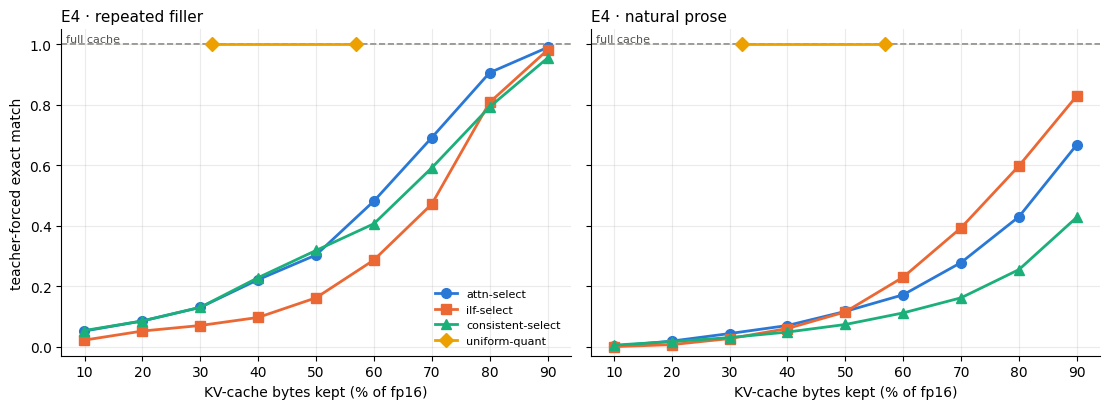

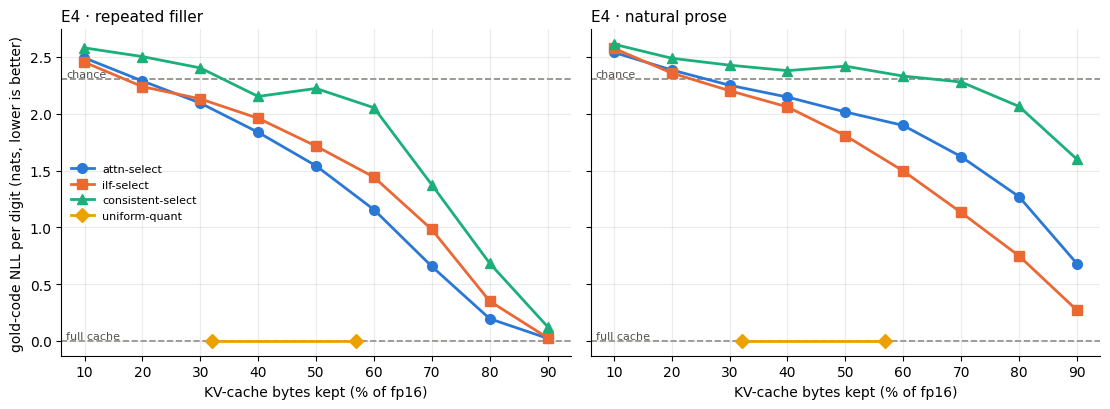

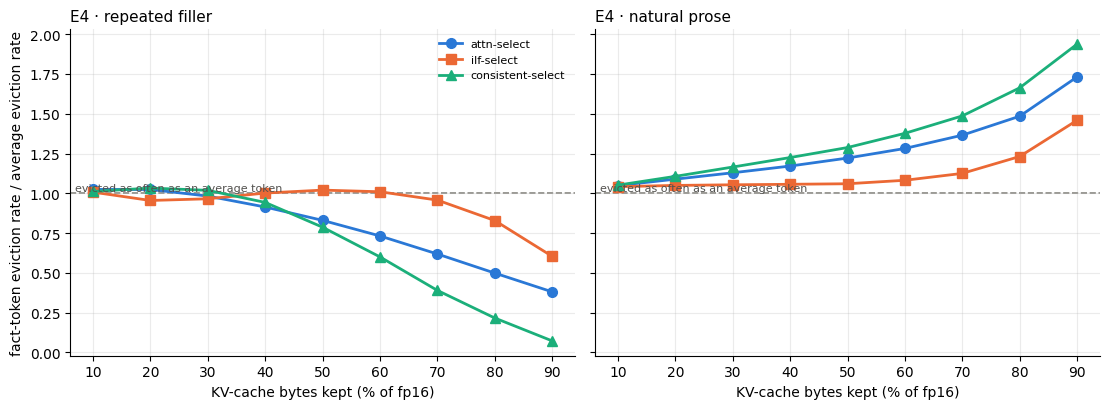

===== e4 finished in 61.3 min =====


In [ ]:
E4_FAMILIES = {"attn-select": {}, "ilf-select": {"lam": LAMBDA}, "consistent-select": {"score_mode": "mix", "layer_mix": 1.0}}

if RUN_E4:
    exp_start("e4")
    e4_budgets = sorted({0.1, 0.2, *KEEP_GRID})
    parts = []
    for hs in ("repeat", "natural"):
        docs, tags = get_docs(hs), {"haystack": HAYSTACK_LABEL[hs]}
        arms = reference_arms(tags) + [Arm(select_cfg(fam, b, **kw), tags=tags)
                                       for b in e4_budgets for fam, kw in E4_FAMILIES.items()]
        print(f"--- {HAYSTACK_LABEL[hs]}: {len(tokenizer(docs[0][0]).input_ids)} tokens in document 0 ---")
        parts.append(run_arms(model, tokenizer, arms, docs, generate=EXP_GENERATE, store="e4"))
    e4_raw = pd.concat(parts, ignore_index=True)
    save_table(e4_raw, MODEL_ID, "e4_haystack_raw")
    e4 = add_eviction_ratio(summarize_arms(e4_raw, by=["haystack"]))
    e4["series"] = e4.apply(plot_family, axis=1)
    save_table(e4, MODEL_ID, "e4_haystack")
    display(e4.pivot_table(index=["series", "budget"], columns="haystack", values="tf_exact").round(3))
    display(e4[e4["kind"] == "select"].pivot_table(index=["series", "budget"], columns="haystack",
                                                   values="fact_eviction_ratio").round(2))

    e4_paired = pd.DataFrame([row for hs in ("repeated filler", "natural prose") for b in e4_budgets
                              for row in paired_vs(e4_raw[e4_raw["haystack"] == hs], f"attn-select@{budget_tag(b)}",
                                                   [f"{fam}@{budget_tag(b)}" for fam in E4_FAMILIES],
                                                   extra={"haystack": hs, "budget": str(b)})])
    save_table(e4_paired, MODEL_ID, "e4_paired_vs_attention")
    display(e4_paired[e4_paired["metric"] == "tf_digit_acc"].round(3))

    for metric, ylabel in (("tf_exact", "teacher-forced exact match"),
                           ("gold_nll", "gold-code NLL per digit (nats, lower is better)"),
                           ("fact_eviction_ratio", "fact-token eviction rate / average eviction rate")):
        fig, axes = panels(2)
        for ax, haystack in zip(axes, ("repeated filler", "natural prose")):
            part = e4[e4["haystack"] == haystack]
            if metric == "fact_eviction_ratio":
                part, refs = part[part["kind"] == "select"], [(1.0, "evicted as often as an average token")]
            else:
                refs = [(full_value(part, metric), "full cache")] + ([(CHANCE_NLL, "chance")] if metric == "gold_nll" else [])
                part = part[part["kind"] != "full"]
            draw_series(ax, part, "kv_bytes_pct", metric, "series", order=[*E4_FAMILIES, "uniform-quant"], refs=refs)
            style_axis(ax, "KV-cache bytes kept (% of fp16)", ylabel if ax is axes[0] else "", f"E4 · {haystack}",
                       legend=ax is axes[0], unit=metric == "tf_exact")
        save_show(fig, f"e4_haystack_{metric}")
    exp_end("e4")

## 16. E6 · Diversity over positions or content instead of layers
Two selectors that diversify along a different axis than ILF, compared with plain attention, ILF and
consistent selection on both haystacks:
* **segment**: the document is cut into `n_segments` equal blocks and every block keeps the same share of
  its tokens (ranked by attention inside the block). This targets the recency concentration seen in the
  first run, where almost only the last facts survived.
* **idf**: `a·(1 + λ·log(M / count))`, where `count` is how often the token's id occurs in the document. This
  is the literal tf-idf analogue: rare tokens are boosted.

Caveat for the write-up: on the repeated-filler haystack the fact tokens are almost the only rare tokens,
so `idf` is close to an oracle there by construction. Only its result on natural prose is evidence.

===== e6 started 2026-11-18T13:26:13+00:00 =====
--- repeated filler ---
                          full [window]: tf-exact 1.000  gold NLL 0.00  needle kept 1.00  KV 100.0%  (64 s, ~22 min left)
                 attention@20% [window]: tf-exact 0.085  gold NLL 2.29  needle kept 0.18  KV 20.0%  (60 s, ~21 min left)
                   ilf λ=1@20% [window]: tf-exact 0.052  gold NLL 2.24  needle kept 0.24  KV 20.0%  (60 s, ~19 min left)
                consistent@20% [window]: tf-exact 0.085  gold NLL 2.50  needle kept 0.17  KV 20.0%  (60 s, ~18 min left)
                   segment@20% [window]: tf-exact 0.022  gold NLL 2.44  needle kept 0.23  KV 20.0%  (60 s, ~17 min left)
                 idf λ=0.5@20% [window]: tf-exact 0.105  gold NLL 2.15  needle kept 0.22  KV 20.0%  (60 s, ~16 min left)
                   idf λ=1@20% [window]: tf-exact 0.115  gold NLL 2.14  needle kept 0.22  KV 20.0%  (60 s, ~15 min left)
                   idf λ=2@20% [window]: tf-exact 0.115  gold NLL 2.14  needle 

budget                        0.2    0.7    0.9
haystack        arm                            
repeated filler attention   0.085  0.692  0.990
                ilf λ=1     0.052  0.472  0.982
                consistent  0.085  0.592  0.955
                segment     0.022  0.795  0.993
                idf λ=0.5   0.105  0.882  0.998
                idf λ=1     0.115  0.895  1.000
                idf λ=2     0.115  0.915  1.000
natural prose   attention   0.018  0.278  0.668
                ilf λ=1     0.007  0.393  0.830
                consistent  0.017  0.162  0.428
                segment     0.002  0.223  0.645
                idf λ=0.5   0.012  0.278  0.697
                idf λ=1     0.013  0.283  0.700
                idf λ=2     0.012  0.292  0.702

tf_digit_acc


budget                        0.2    0.7    0.9
haystack        arm                            
repeated filler attention   0.217  0.850  0.998
                ilf λ=1     0.206  0.752  0.994
                consistent  0.214  0.824  0.990
                segment     0.193  0.917  0.999
                idf λ=0.5   0.260  0.963  1.000
                idf λ=1     0.267  0.968  1.000
                idf λ=2     0.271  0.975  1.000
natural prose   attention   0.147  0.504  0.853
                ilf λ=1     0.170  0.718  0.949
                consistent  0.129  0.408  0.718
                segment     0.111  0.463  0.856
                idf λ=0.5   0.144  0.532  0.880
                idf λ=1     0.143  0.543  0.888
                idf λ=2     0.140  0.550  0.890

gold_nll


budget                        0.2    0.7    0.9
haystack        arm                            
repeated filler attention   2.289  0.656  0.023
                ilf λ=1     2.239  0.981  0.027
                consistent  2.504  1.375  0.125
                segment     2.444  0.420  0.016
                idf λ=0.5   2.154  0.296  0.005
                idf λ=1     2.137  0.251  0.000
                idf λ=2     2.142  0.207  0.000
natural prose   attention   2.386  1.623  0.681
                ilf λ=1     2.359  1.131  0.271
                consistent  2.489  2.280  1.600
                segment     2.492  1.727  0.745
                idf λ=0.5   2.413  1.731  0.695
                idf λ=1     2.420  1.746  0.705
                idf λ=2     2.426  1.716  0.705

fact_eviction_ratio


budget                        0.2    0.7    0.9
haystack        arm                            
repeated filler attention   1.024  0.618  0.380
                ilf λ=1     0.955  0.957  0.604
                consistent  1.033  0.390  0.072
                segment     0.965  0.534  0.383
                idf λ=0.5   0.978  0.516  0.309
                idf λ=1     0.969  0.508  0.307
                idf λ=2     0.963  0.504  0.307
natural prose   attention   1.089  1.365  1.731
                ilf λ=1     1.049  1.125  1.459
                consistent  1.106  1.486  1.937
                segment     1.109  1.431  1.999
                idf λ=0.5   1.128  1.519  1.899
                idf λ=1     1.134  1.535  1.887
                idf λ=2     1.137  1.544  1.871

Saved /content/drive/MyDrive/kv_cache_results2_l4/Qwen__Qwen3-4B/e6_paired_vs_attention.csv


,haystack,budget,a,b,metric,n,mean_a,mean_b,diff_b_minus_a,ci_lo,ci_hi,a_better,b_better
0,repeated filler,0.2,attention@20%,ilf λ=1@20%,tf_digit_acc,600,0.217,0.206,-0.011,-0.030,0.008,118,136
2,repeated filler,0.2,attention@20%,consistent@20%,tf_digit_acc,600,0.217,0.214,-0.003,-0.014,0.007,107,106
4,repeated filler,0.2,attention@20%,segment@20%,tf_digit_acc,600,0.217,0.193,-0.024,-0.038,-0.008,162,127
6,repeated filler,0.2,attention@20%,idf λ=0.5@20%,tf_digit_acc,600,0.217,0.260,0.043,0.033,0.053,56,129
8,repeated filler,0.2,attention@20%,idf λ=1@20%,tf_digit_acc,600,0.217,0.267,0.050,0.040,0.061,64,147
10,repeated filler,0.2,attention@20%,idf λ=2@20%,tf_digit_acc,600,0.217,0.271,0.054,0.043,0.065,66,152
12,repeated filler,0.7,attention@70%,ilf λ=1@70%,tf_digit_acc,600,0.850,0.752,-0.098,-0.128,-0.071,218,74
14,repeated filler,0.7,attention@70%,consistent@70%,tf_digit_acc,600,0.850,0.824,-0.026,-0.045,-0.005,135,72
16,repeated filler,0.7,attention@70%,segment@70%,tf_digit_acc,600,0.850,0.917,0.067,0.052,0.084,71,157
18,repeated filler,0.7,attention@70%,idf λ=0.5@70%,tf_digit_acc,600,0.850,0.963,0.113,0.098,0.129,6,172


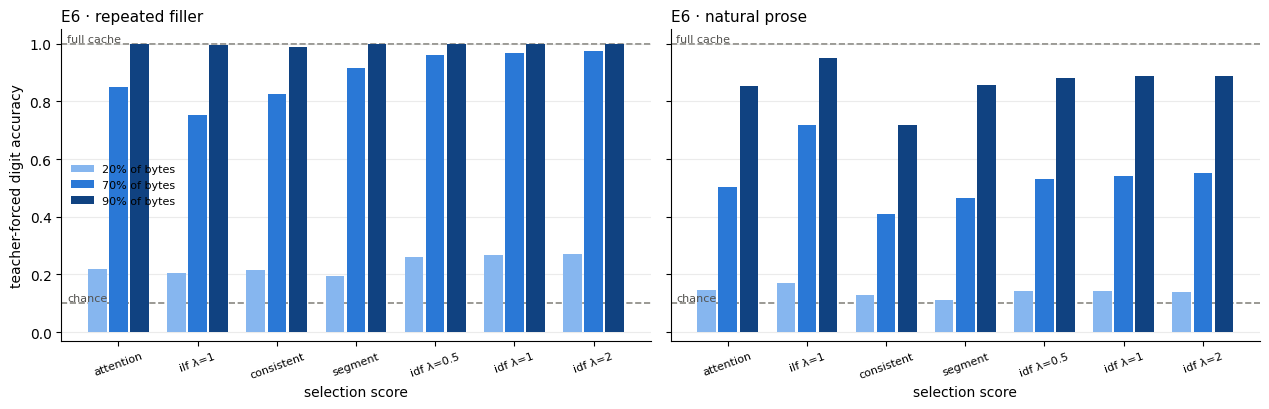

===== e6 finished in 45.0 min =====


In [ ]:
E6_ARMS = {"attention": {}, "ilf λ=1": {"lam": 1.0}, "consistent": {"score_mode": "mix", "layer_mix": 1.0},
           "segment": {"score_mode": "segment"}, "idf λ=0.5": {"score_mode": "idf", "lam": 0.5},
           "idf λ=1": {"score_mode": "idf", "lam": 1.0}, "idf λ=2": {"score_mode": "idf", "lam": 2.0}}

if RUN_E6:
    exp_start("e6")
    e6_budgets = sorted({0.2, *PROBE_BUDGETS})[:3]
    parts = []
    for hs in ("repeat", "natural"):
        haystack = HAYSTACK_LABEL[hs]
        arms = [Arm(make_config("full", "full"), tags={"haystack": haystack, "arm": "full"})]
        arms += [Arm(select_cfg(label, b, **kw), tags={"haystack": haystack, "arm": label})
                 for b in e6_budgets for label, kw in E6_ARMS.items()]
        print(f"--- {haystack} ---")
        parts.append(run_arms(model, tokenizer, arms, get_docs(hs), generate=EXP_GENERATE, store="e6"))
    e6_raw = pd.concat(parts, ignore_index=True)
    save_table(e6_raw, MODEL_ID, "e6_content_diversity_raw")
    e6 = add_eviction_ratio(summarize_arms(e6_raw, keys=["haystack", "arm", "budget", "kind"]))
    save_table(e6, MODEL_ID, "e6_content_diversity")
    e6_sel = e6[e6["kind"] == "select"]
    for metric in ("tf_exact", "tf_digit_acc", "gold_nll", "fact_eviction_ratio"):
        print(metric)
        display(e6_sel.pivot_table(index=["haystack", "arm"], columns="budget", values=metric, sort=False).round(3))

    e6_paired = pd.DataFrame([row for hs in ("repeated filler", "natural prose") for b in e6_budgets
                              for row in paired_vs(e6_raw[e6_raw["haystack"] == hs], f"attention@{budget_tag(b)}",
                                                   [f"{label}@{budget_tag(b)}" for label in E6_ARMS],
                                                   extra={"haystack": hs, "budget": str(b)})])
    save_table(e6_paired, MODEL_ID, "e6_paired_vs_attention")
    display(e6_paired[e6_paired["metric"] == "tf_digit_acc"].round(3))

    fig, axes = panels(2, width=6.4)
    for ax, haystack in zip(axes, ("repeated filler", "natural prose")):
        part = e6_sel[e6_sel["haystack"] == haystack]
        table = part.pivot(index="arm", columns="budget", values="tf_digit_acc").reindex(
            index=list(E6_ARMS), columns=[str(b) for b in e6_budgets])
        table.columns = [f"{budget_tag(b)} of bytes" for b in e6_budgets]
        grouped_bars(ax, table, ORDINAL_BLUES,
                     refs=[(full_value(e6[e6["haystack"] == haystack], "tf_digit_acc"), "full cache"), (0.1, "chance")])
        style_axis(ax, "selection score", "teacher-forced digit accuracy" if ax is axes[0] else "", f"E6 · {haystack}",
                   legend=ax is axes[0], unit=True)
        ax.grid(axis="x", visible=False)
        ax.tick_params(axis="x", labelrotation=20)
    save_show(fig, "e6_content_diversity")
    exp_end("e6")

## 17. Memory and decode latency
Default full-run workload: T4 profile batch 1 × 2,048 tokens; L4 profile batch 2 × 4,096 tokens.
The sequence is capped to reserve room for decoding within `MAX_LEN`. To reduce memory further, use
`GPU_PROFILE = "t4"` or reduce `BENCH_SEQ_LEN` in §2. Compare latency only at the same batch and length.

Workload: batch `BENCH_BATCH` × `BENCH_SEQ_LEN` tokens, `BENCH_DECODE_TOKENS` timed decode steps, for 22 methods
(full; uniform 8/4/2-bit; attention and ILF selection and mixed precision at 10%, 20%, `int4` and `int8` bytes;
consistent selection at 10% and 20%).

* **kv_bytes_pct / kv_MiB_logical**: stored KV bytes, quantization metadata included.
* **kv_MiB_measured**: GPU memory still allocated after prefill and compression.
* **prefill_peak_MiB / decode_peak_MiB**: peak extra memory. Compression runs after prefill, so the prefill peak
  is the same for every method.
* **decode_ms_per_token**: wall time per decode step for the whole batch, CUDA-synchronized.

**Timing protocol.** In the first run the order of the methods set the numbers (the first ones measured 46–97
ms/token, later selection methods 27–33). So: one untimed pass over every method, then `BENCH_REPEATS` repeats
in a freshly shuffled order; the table reports the median and interquartile range across repeats. For the
cleanest numbers, run this section in a fresh runtime: set every `RUN_E*` to False (their results are already
on disk) and run all cells. Quantized tokens are dequantized in plain PyTorch at every step, so the latency
cost of quantization here is our unfused implementation's, not the method's.

In [ ]:
# ---- Memory and decode latency at a fixed workload (batch x sequence length) ----
def benchmark_memory_latency(model, tokenizer, cfg, batch, seq_len, decode_tokens, warmup=3):
    ids = []
    for s in range(batch):
        doc, _ = make_retrieval_doc(20, seq_len // 10, seed=1000 + s)
        t = tokenizer(doc).input_ids
        while len(t) < seq_len:
            t = t + t
        ids.append(t[:seq_len])
    input_ids = torch.tensor(ids, device=model.device)
    cuda = input_ids.is_cuda
    gc.collect()
    if cuda:
        torch.cuda.empty_cache()
        torch.cuda.synchronize()
        base = torch.cuda.memory_allocated()
        torch.cuda.reset_peak_memory_stats()
    prefix, logits = prefill_and_compress(model, input_ids, cfg)
    nxt = logits.argmax(-1, keepdim=True)
    del logits
    row = {**describe(cfg), "batch": batch, "seq_len": seq_len, "kv_bytes_pct": prefix.stats["kv_bytes_pct"],
           "kv_MiB_logical": prefix.stats["kv_bytes"] / 2**20,
           "prefill_compress_ms": 1000 * prefix.stats["prefill_compress_s"]}
    if cuda:
        torch.cuda.synchronize()
        row["kv_MiB_measured"] = (torch.cuda.memory_allocated() - base) / 2**20
        row["prefill_peak_MiB"] = (torch.cuda.max_memory_allocated() - base) / 2**20
        torch.cuda.reset_peak_memory_stats()
    cache, pos, times = prefix.make_cache(), seq_len, []
    for step in range(decode_tokens + warmup):
        if cuda:
            torch.cuda.synchronize()
        t0 = time.perf_counter()
        nxt = extend(model, cache, nxt, pos)[:, -1].argmax(-1, keepdim=True)
        if cuda:
            torch.cuda.synchronize()
        if step >= warmup:
            times.append(time.perf_counter() - t0)
        pos += 1
    row["decode_ms_per_token"] = 1000 * sum(times) / len(times)
    if cuda:
        row["decode_peak_MiB"] = (torch.cuda.max_memory_allocated() - base) / 2**20
    del cache, prefix
    return row


def bench_methods(lam=LAMBDA):
    methods = [make_config("full", "full")] + [make_config(f"quant-int{b}", "quant", quant_bits=b) for b in (8, 4, 2)]
    for b in (0.1, 0.2, "int4", "int8"):
        t = budget_tag(b)
        methods += [make_config(f"attn-select@{t}", "select", b, 0.0), make_config(f"ilf-select@{t}", "select", b, lam),
                    make_config(f"attn-mixed@{t}", "mixed", b, 0.0), make_config(f"ilf-mixed@{t}", "mixed", b, lam)]
    methods += [make_config(f"consistent-select@{budget_tag(b)}", "select", b, score_mode="mix", layer_mix=1.0)
                for b in (0.1, 0.2)]
    return methods


def bench_once(cfg, seq_len, decode_tokens):
    try:
        return benchmark_memory_latency(model, tokenizer, cfg, BENCH_BATCH, seq_len, decode_tokens)
    except torch.cuda.OutOfMemoryError:
        gc.collect()
        torch.cuda.empty_cache()
        print(f"out of memory: {cfg.name} at batch {BENCH_BATCH} x {seq_len}; lower BENCH_BATCH and rerun this cell")
        return {**describe(cfg), "batch": BENCH_BATCH, "seq_len": seq_len, "oom": True}


if RUN_BENCH:
    exp_start("bench")
    BENCH_METHODS = bench_methods()
    seq_len = min(BENCH_SEQ_LEN, MAX_LEN - BENCH_DECODE_TOKENS - 8)
    print(f"warm-up pass over {len(BENCH_METHODS)} methods (not timed)")
    for cfg in BENCH_METHODS:
        bench_once(cfg, seq_len, 4)
    runs = []
    for r in range(BENCH_REPEATS):
        order = BENCH_METHODS[:]
        random.Random(SEED + r).shuffle(order)
        for cfg in order:
            runs.append({**bench_once(cfg, seq_len, BENCH_DECODE_TOKENS), "repeat": r})
        print(f"repeat {r + 1}/{BENCH_REPEATS} done")
    bench_runs = pd.DataFrame(runs)
    save_table(bench_runs, MODEL_ID, "memory_latency_runs")

    timed = ["decode_ms_per_token", "prefill_compress_ms"]
    memory = [c for c in ["kv_bytes_pct", "kv_MiB_logical", "kv_MiB_measured", "prefill_peak_MiB", "decode_peak_MiB"]
              if c in bench_runs]
    keys = ["method", "family", "kind", "budget", "lambda", "batch", "seq_len"]
    ok = bench_runs[bench_runs.get("oom", pd.Series(False, index=bench_runs.index)) != True]  # noqa: E712
    g = ok.groupby(keys, sort=False)
    bench_df = g[memory + timed].median()
    for c in timed:
        bench_df[f"{c}_iqr"] = g[c].quantile(0.75) - g[c].quantile(0.25)
    bench_df = bench_df.reset_index()
    if "kv_MiB_measured" in bench_df:
        bench_df["measured_vs_logical"] = bench_df["kv_MiB_measured"] / bench_df["kv_MiB_logical"]
        off = bench_df[(bench_df["measured_vs_logical"] - 1).abs() > 0.05]
        if len(off):
            print("measured KV memory more than 5% off the byte accounting:", off["method"].tolist())
    save_table(bench_df, MODEL_ID, "memory_latency")
    display(bench_df.round(2))
    exp_end("bench")

===== bench started 2026-11-18T14:11:11+00:00 =====
warm-up pass over 22 methods (not timed)
repeat 1/3 done


## 18. Optional: MMLU and LongBench
Both are off by default (`RUN_MMLU`, `RUN_LONGBENCH`). Methods: full, uniform 8/4/2-bit, and attention, ILF and
consistent selection at the probe budgets (10 methods).

* **MMLU** is a no-harm check on short contexts: log-likelihood scoring, few-shot, no chat template.
* **LongBench** runs the full cache first and keeps only the tasks where it scores at least
  `max(LONGBENCH_MIN_FULL, 2 × chance)`; on Qwen2.5-0.5B the full cache was at chance on passage retrieval.
  With `LONGBENCH_CHAT_TEMPLATE`, each prompt is wrapped in the chat template with thinking turned off
  (`enable_thinking=False`, the Qwen3 switch), so the model answers directly instead of spending its
  generation budget on a reasoning block. With `QUERY_AWARE = False`, the prompt is split where the question
  starts, inside the user turn: the document is compressed before the question is seen, and the question plus
  the assistant header run on the compressed cache.
* Each method's results are checkpointed, so a long LongBench run resumes per method.

In [ ]:
OPTIONAL_BENCHMARKS = RUN_MMLU or RUN_LONGBENCH
if OPTIONAL_BENCHMARKS:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "lm_eval[hf,longbench]==0.4.11",
                    "transformers==4.57.1"], check=True)
    from lm_eval import evaluator
    from lm_eval.api.model import LM
    from tqdm.auto import tqdm
    VERSIONS["lm_eval"] = version("lm_eval")
    update_manifest(versions=VERSIONS)
else:
    LM = object  # lets the definitions below run without lm_eval installed

In [ ]:
# Where the question starts in each LongBench prompt. With QUERY_AWARE = False, everything
# before the marker is the reusable prefix: it is compressed *without seeing the question*,
# then the question is run on top of the compressed cache (prefix-caching setup).
LONGBENCH_QUESTION_MARKERS = [
    "\n\nAnswer the question based on the given passages.",          # hotpotqa, 2wikimqa, musique
    "\n\nNow, answer the following question based on the above text",  # multifieldqa_en
    "\n\n Answer the question based on the above article",            # qasper
    "\n\nNow, answer the question based on the story",                 # narrativeqa
    "\n\nThe following is an abstract.",                               # passage_retrieval_en
    "\n\nNow, write a one-page summary of the report.",                # gov_report
]


def middle_truncate(ids, max_len):
    """LongBench convention: keep the first and last halves of an over-long prompt."""
    if len(ids) <= max_len:
        return ids
    half = max_len // 2
    return ids[:half] + ids[len(ids) - (max_len - half):]


class CompressedKVLM(LM):
    """lm-evaluation-harness model that runs every request through a compressed KV cache.

    loglikelihood (MMLU): the context minus its last token is the prefix; it is compressed,
    then [last context token + continuation] is scored on top of the compressed cache, so
    every scored token depends on the compressed cache. Requests sharing a context reuse
    one compressed prefix.
    generate_until (LongBench): prefix = prompt up to the question (QUERY_AWARE=False) or
    the whole prompt minus its last token (QUERY_AWARE=True); greedy decoding afterwards."""

    def __init__(self, model, tokenizer, cfg, max_input_tokens=4096, query_aware=False,
                 markers=LONGBENCH_QUESTION_MARKERS, chat=False):
        super().__init__()
        self.model, self.tokenizer, self.cfg = model, tokenizer, cfg
        self.chat = chat and getattr(tokenizer, "chat_template", None) is not None
        self.max_input_tokens, self.query_aware, self.markers = max_input_tokens, query_aware, markers
        self.device = model.device
        self.compression_stats = []

    def _ids(self, text, special=True):
        return self.tokenizer(text, add_special_tokens=special).input_ids

    def _tensor(self, ids):
        return torch.tensor([ids], device=self.device)

    def _compress(self, prefix_ids):
        prefix, _ = prefill_and_compress(self.model, self._tensor(prefix_ids), self.cfg)
        self.compression_stats.append(prefix.stats)
        return prefix

    def loglikelihood(self, requests, disable_tqdm=False):
        groups = defaultdict(list)
        for i, req in enumerate(requests):
            context, continuation = req.args
            groups[context].append((i, continuation))
        results = [None] * len(requests)
        for context, items in tqdm(groups.items(), desc=f"loglikelihood [{self.cfg.name}]", disable=disable_tqdm):
            n_space = len(context) - len(context.rstrip())  # move trailing spaces into the continuation
            ctx = context[:len(context) - n_space] if n_space else context
            ctx_ids = self._ids(ctx)
            conts = []
            for i, cont in items:
                cont = context[len(ctx):] + cont
                conts.append((i, self._ids(ctx + cont)[len(ctx_ids):]))
            longest = max(len(c) for _, c in conts)
            ctx_ids = ctx_ids[-(self.max_input_tokens - longest):]
            if len(ctx_ids) < 2:
                raise ValueError("context too short to split into prefix + last token")
            prefix = self._compress(ctx_ids[:-1])
            for i, cont_ids in conts:
                feed = self._tensor([ctx_ids[-1]] + cont_ids[:-1])
                logits = extend(self.model, prefix.make_cache(), feed, prefix.length, all_logits=True)[0]
                logprobs = logits.log_softmax(-1)
                target = torch.tensor(cont_ids, device=logits.device)
                ll = logprobs.gather(-1, target[:, None]).sum().item()
                results[i] = (ll, bool((logits.argmax(-1) == target).all()))
        return results

    def _split(self, context):
        if not self.query_aware:
            cut = max(context.rfind(m) for m in self.markers)
            if cut > 0:
                return context[:cut], context[cut:]
        return None, None

    def generate_until(self, requests, disable_tqdm=False):
        outputs = []
        for req in tqdm(requests, desc=f"generate [{self.cfg.name}]", disable=disable_tqdm):
            context, gen_kwargs = req.args
            if self.chat:  # the question marker stays inside the user turn, so the split below still works
                context = self.tokenizer.apply_chat_template([{"role": "user", "content": context}], tokenize=False,
                                                             add_generation_prompt=True, enable_thinking=False)
            until = gen_kwargs.get("until") or []
            until = [until] if isinstance(until, str) else list(until)
            max_new = int(gen_kwargs.get("max_gen_toks", 128))
            budget = self.max_input_tokens - max_new
            prefix_str, suffix_str = self._split(context)
            if prefix_str is None:
                ids = middle_truncate(self._ids(context), budget)
                prefix_ids, suffix_ids = ids[:-1], ids[-1:]
            else:
                suffix_ids = self._ids(suffix_str, special=False)
                prefix_ids = middle_truncate(self._ids(prefix_str), budget - len(suffix_ids))
            prefix = self._compress(prefix_ids)
            outputs.append(greedy_generate(self.model, self.tokenizer, prefix, self._tensor(suffix_ids),
                                           max_new, until))
        return outputs

    def loglikelihood_rolling(self, requests, disable_tqdm=False):
        raise NotImplementedError("perplexity tasks are not used in this project")


def mean_compression_stats(stats_list):
    if not stats_list:
        return {}
    keys = [k for k in stats_list[0] if isinstance(stats_list[0][k], (int, float))]
    return {k: sum(s.get(k, 0) for s in stats_list) / len(stats_list) for k in keys}


def run_lm_eval(model, tokenizer, cfg, tasks, limit, num_fewshot=None, max_input_tokens=4096,
                query_aware=False, chat=False):
    lm = CompressedKVLM(model, tokenizer, cfg, max_input_tokens, query_aware, chat=chat)
    results = evaluator.simple_evaluate(
        model=lm, tasks=tasks, num_fewshot=num_fewshot, limit=limit, log_samples=False,
        random_seed=42, numpy_random_seed=42, torch_random_seed=42, fewshot_random_seed=42,
    )
    return results, mean_compression_stats(lm.compression_stats)


def headline_metric(task_results):
    """Primary metric of one lm-eval task result dict (accuracy for MMLU, score for LongBench)."""
    for key in ("acc,none", "score,none", "exact_match,none"):
        if key in task_results:
            return key.split(",")[0], task_results[key]
    raise KeyError(f"no known metric in {list(task_results)}")


def run_benchmark_suite(model, tokenizer, methods, tasks, limit, num_fewshot=None, max_input_tokens=4096,
                        store=None, chat=False):
    """One row per (method, task). With `store`, each method's rows are saved to EXP_OUT/<store>/<method>.csv
    and loaded from there on later calls."""
    frames = []
    out_dir = EXP_OUT / store if store else None
    if out_dir:
        out_dir.mkdir(parents=True, exist_ok=True)
    for cfg in methods:
        tag = hashlib.sha1(json.dumps([asdict(cfg), tasks, limit, num_fewshot, max_input_tokens, chat, QUERY_AWARE],
                                      sort_keys=True, default=str).encode()).hexdigest()[:10]
        path = out_dir / f"{cfg.name.replace('/', '_')}-{tag}.csv" if out_dir else None
        if path is not None and path.exists():
            frames.append(pd.read_csv(path, dtype={"budget": str}))
            continue
        results, stats = run_lm_eval(model, tokenizer, cfg, tasks, limit, num_fewshot, max_input_tokens,
                                     QUERY_AWARE, chat)
        rows = []
        for task in tasks:
            metric, value = headline_metric(results["results"][task])
            rows.append({**describe(cfg), "task": task, "metric": metric, "value": value,
                         **{k: stats.get(k) for k in STAT_COLUMNS}})
        df = pd.DataFrame(rows)
        if path is not None:
            df.to_csv(path, index=False)
        frames.append(df)
        print(f"{cfg.name:>24}: " + ", ".join(f"{r['task']}={r['value']:.3f}" for r in rows))
    return pd.concat(frames, ignore_index=True)


LONGBENCH_CHANCE = {"longbench_passage_retrieval_en": 1 / 30}  # F1 tasks: chance is about 0

In [ ]:
if OPTIONAL_BENCHMARKS:
    OPT_METHODS = ([make_config("full", "full")]
                   + [make_config(f"quant-int{b}", "quant", quant_bits=b) for b in (8, 4, 2)]
                   + [select_cfg(fam, b, **kw) for b in PROBE_BUDGETS
                      for fam, kw in (("attn-select", {}), ("ilf-select", {"lam": LAMBDA}),
                                      ("consistent-select", {"score_mode": "mix", "layer_mix": 1.0}))])
    print(f"{len(OPT_METHODS)} methods:", [m.name for m in OPT_METHODS])

if RUN_MMLU:
    exp_start("mmlu")
    mmlu_df = run_benchmark_suite(model, tokenizer, OPT_METHODS, MMLU_TASKS, MMLU_LIMIT, MMLU_FEWSHOT, MAX_LEN,
                                  store="mmlu")
    save_table(mmlu_df, MODEL_ID, "mmlu")
    display(mmlu_df[["method", "task", "value", "kv_bytes_pct"]].round(3))
    exp_end("mmlu")

if RUN_LONGBENCH:
    exp_start("longbench")
    lb_full = run_benchmark_suite(model, tokenizer, OPT_METHODS[:1], LONGBENCH_TASKS, LONGBENCH_LIMIT, None, MAX_LEN,
                                  store="longbench", chat=LONGBENCH_CHAT_TEMPLATE)
    full_scores = lb_full.set_index("task")["value"]
    lb_tasks = [t for t in LONGBENCH_TASKS
                if full_scores[t] >= max(LONGBENCH_MIN_FULL, 2 * LONGBENCH_CHANCE.get(t, 0.0))]
    dropped = sorted(set(LONGBENCH_TASKS) - set(lb_tasks))
    print("full-cache scores:", full_scores.round(3).to_dict(), "| dropped (too close to chance):", dropped)
    update_manifest(longbench={"full_scores": full_scores.to_dict(), "kept_tasks": lb_tasks, "dropped": dropped})
    parts = [lb_full[lb_full["task"].isin(lb_tasks)]]
    if lb_tasks:
        parts.append(run_benchmark_suite(model, tokenizer, OPT_METHODS[1:], lb_tasks, LONGBENCH_LIMIT, None, MAX_LEN,
                                         store="longbench", chat=LONGBENCH_CHAT_TEMPLATE))
    longbench_df = pd.concat(parts, ignore_index=True)
    save_table(longbench_df, MODEL_ID, "longbench")
    display(longbench_df.pivot_table(index="method", columns="task", values="value", sort=False).round(3))
    exp_end("longbench")

## 19. Summary and export
Collects every experiment's summary table that exists on disk (from this session or earlier ones) into
`summary_all.csv` with an `experiment` column, writes `figures_index.md`, and zips the results folder.

In [ ]:
SUMMARY_FILES = {"E0": "e0_budget_sweep", "E1 knock-out": "e1_knockout", "E1 single layer": "e1_single_layer",
                 "E1 oracle": "e1_oracle_keep", "E2": "e2_consistency", "E3": "e3_scoring_signal",
                 "E4": "e4_haystack", "E5": "e5_tier_split", "E6": "e6_content_diversity",
                 "memory and latency": "memory_latency", "MMLU": "mmlu", "LongBench": "longbench"}
_parts = []
for name, stem in SUMMARY_FILES.items():
    path = EXP_OUT / f"{stem}.csv"
    if path.exists():
        _parts.append(pd.read_csv(path, dtype={"budget": str}).assign(experiment=name))
if _parts:
    summary_all = pd.concat(_parts, ignore_index=True)
    first = ["experiment", "method", "haystack", "budget", "tf_exact", "tf_digit_acc", "gold_nll", "kv_bytes_pct"]
    summary_all = summary_all[[c for c in first if c in summary_all] + [c for c in summary_all if c not in first]]
    save_table(summary_all, MODEL_ID, "summary_all")
    display(summary_all.groupby("experiment", sort=False).size().rename("rows").to_frame())
else:
    print("no experiment results found in", EXP_OUT)

_figures = sorted(p.name for p in EXP_OUT.glob("*.png"))
(EXP_OUT / "figures_index.md").write_text(
    f"# Figures for {MODEL_ID} ({PRESET})\n\n" + "\n".join(f"- [{n}]({n})" for n in _figures) + "\n")
print(f"{len(_figures)} figures listed in figures_index.md")
_zip = shutil.make_archive(str(EXP_OUT), "zip", EXP_OUT)
update_manifest(last_session_finished=_now())
print("zipped results:", _zip)

**Limitations to state in the write-up.** Batches are unpadded (equal-length inputs). Quantized tokens are
dequantized every decode step in PyTorch, not with a fused kernel, so latency includes that overhead. The prefill
peak is not reduced, because compression happens after prefill. Retrieval is synthetic (5-digit codes); MMLU
contexts are short, so most of each prompt sits in the protected window. One model per run: compare across
models only on matching presets and haystacks.

References: [Transformers cache guide](https://huggingface.co/docs/transformers/v4.57.1/en/cache_explanation),
[Attention interface](https://huggingface.co/docs/transformers/v4.57.1/en/attention_interface),
[LM Evaluation Harness API](https://github.com/EleutherAI/lm-evaluation-harness/blob/main/docs/python-api.md),
SnapKV (Li et al., 2024), KIVI (Liu et al., 2024), KVzip ([arXiv 2505.23416](https://arxiv.org/abs/2505.23416)).